#### Práctica 4: Meta aprendizaje 

### Introducción
Los métodos de ensamble en aprendizaje automático permiten combinar diferentes modelos con el objetivo de mejorar la capacidad predictiva, reducir errores y obtener resultados más estables. Entre las principales estrategias se encuentran Bagging, Boosting, Voting y Stacking, las cuales utilizan distintos mecanismos para aprovechar las predicciones de múltiples clasificadores. (Ligdieli & Ligdieli, 2019) 

En esta práctica se analizaron estas técnicas utilizando dos conjuntos de datos. El primero corresponde a un problema de clasificación multiclase relacionado con la deserción estudiantil (Realinho et al., 2021), mientras que el segundo utiliza el conjunto Bank Marketing para predecir si un cliente contratará un depósito bancario (Moro et al., 2014). 

### Libreria

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import time
import joblib

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
      AdaBoostClassifier, 
      VotingClassifier, 
      StackingClassifier, 
      RandomForestClassifier,
      ExtraTreesClassifier
)
from sklearn.metrics import f1_score, recall_score,  make_scorer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict,  RandomizedSearchCV
from scipy.stats import randint, uniform , loguniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.preprocessing import LabelEncoder, FunctionTransformer
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

## Parte 1

### Varianza 

Primero se analizará cómo el uso de ensambles puede ayudar a reducir la varianza, por lo que compararemos un árbol de decisión sin límite de profundidad con un modelo *Bagging*, que combina múltiples árboles entrenados sobre diferentes muestras de los datos. (¿Qué Es el Bagging? | IBM, 2026)

Los árboles de decisión profundos pueden presentar una varianza elevada, ya que pequeños cambios en los datos de entrenamiento pueden producir árboles muy diferentes por la tendencias que tienen estos a sobreajustarse. Bagging busca reducir esto  mediante el entrenamiento de varios modelos independientes y la combinación de sus predicciones por votación.

Se evaluará el desempeño utilizando F1-macro y los mismos cinco pliegues estratificados de la Práctica 3. Además, se analizará cómo cambia el desempeño de Bagging al incrementar progresivamente el número de árboles, desde 1 hasta 400.

In [2]:
RANDOM_STATE = 42

# Cargar los archivos originales
train = pd.read_csv("desercion-entrenamiento.csv")
test = pd.read_csv("desercion-prueba.csv")

# Variables disponibles al finalizar el primer semestre
features_1sem = [
    col for col in test.columns
    if col != "id"
]

# Definir predictores y variable objetivo
X = train[features_1sem].copy()
y = train["Target"].copy()

# Verificar las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de clases:")
print(y.value_counts())

# Mismos cinco pliegues de la Práctica 3
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits = list(cv.split(X, y))

print("\nNúmero de pliegues:", len(cv_splits))

Dimensiones de X: (3539, 30)
Dimensiones de y: (3539,)

Distribución de clases:
Target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64

Número de pliegues: 5


Recuperaremos el preprocesamiento utilizado para los árboles de decisión, que consistia en imputar los valores faltantes de las variables categóricas con el valor más frecuente y aplicar One-Hot Encoding. No se requiere estandarización, ya que los árboles de decisión realizan divisiones basadas en los valores de las características y no dependen de sus escalas. El preprocesamiento se ajustará únicamente con los datos de entrenamiento de cada pliegue. 

In [3]:
# Cargar los modelos optimizados de la Práctica 3
modelos_base = joblib.load("modelos_practica3.joblib")

# Recuperar el pipeline del árbol
mejor_arbol = modelos_base["Árbol de decisión"]

# Extraer su preprocesamiento original
preprocesamiento_arbol = clone(
    mejor_arbol.named_steps["preprocesamiento"]
)

print("Preprocesamiento recuperado correctamente.")

# Mostrar las transformaciones y sus columnas
for nombre, transformador, columnas in preprocesamiento_arbol.transformers:
    print(f"\n{nombre}:")
    print(list(columnas))

Preprocesamiento recuperado correctamente.

categoricas:
['Marital status', 'Application mode', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

numericas:
['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


Primero se evaluará un árbol de decisión sin restringir su profundidad, esto va generar que el modelo haga divisiones hasta que pare por sus condiciones de paro natural, lo que causa que aumente su capacidad para ajustarse a los datos de entrenamiento.

Sin embargo, un árbol demasiado complejo puede aprender patrones específicos o ruido del conjunto de entrenamiento, lo que puede perjudicar su capacidad de generalización.El objetivo es establecer un punto de referencia para determinar si Bagging mejora el desempeño de un árbol individual. (¿Qué Es el Bagging? | IBM, 2026)

In [4]:
# Árbol sin límite de profundidad
arbol_completo = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_arbol)),
    ("modelo", DecisionTreeClassifier(
        max_depth=None,
        random_state=RANDOM_STATE
    ))
])

# Evaluación mediante validación cruzada
resultados_arbol = cross_validate(
    arbol_completo,
    X,
    y,
    cv=cv_splits,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

f1_arbol = resultados_arbol["test_score"]
f1_arbol_train = resultados_arbol["train_score"]

print("Árbol sin límite de profundidad")
print(
    f"F1-macro validación: "
    f"{f1_arbol.mean():.4f} ± {f1_arbol.std():.4f}"
)
print(
    f"F1-macro entrenamiento: "
    f"{f1_arbol_train.mean():.4f}"
)
print(
    f"Tiempo promedio de entrenamiento: "
    f"{resultados_arbol['fit_time'].mean():.4f} s"
)

Árbol sin límite de profundidad
F1-macro validación: 0.5957 ± 0.0114
F1-macro entrenamiento: 1.0000
Tiempo promedio de entrenamiento: 0.1115 s


El árbol sin límite de profundidad obtuvo un F1-macro de 0.5957 ± 0.0114 en validación, mientras que en entrenamiento alcanzó 1.0. Esta diferencia indica un claro sobreajuste: el modelo se ajusta perfectamente a los datos de entrenamiento, pero pierde capacidad de generalización ante datos nuevos. Esto justifica evaluar Bagging como una alternativa para reducir la varianza.

Bagging es una técnica de ensamble que entrena múltiples clasificadores utilizando muestras aleatorias de los datos de entrenamiento, obtenidas mediante muestreo con reemplazo. Se utilizarán árboles de decisión sin límite de profundidad como clasificadores base. Sus predicciones se combinarán mediante votación para obtener una clasificación final. 

Se evaluarán ensambles de 1, 5, 10, 20, 50, 100, 200, 300 y 400 árboles, con el objetivo de analizar cómo cambia el F1-macro conforme aumenta el tamaño del ensamble.

In [5]:
cantidades_arboles = [1, 5, 10, 20, 50, 100, 200, 300, 400]

resultados_bagging = {
    n: [] for n in cantidades_arboles
}

sensibilidad_bagging = {
    n: [] for n in cantidades_arboles
}

tiempos_bagging = {
    n: [] for n in cantidades_arboles
}

for fold, (idx_train, idx_val) in enumerate(cv_splits, start=1):

    # Separar entrenamiento y validación
    X_train = X.iloc[idx_train]
    X_val = X.iloc[idx_val]

    y_train = y.iloc[idx_train]
    y_val = y.iloc[idx_val]

    inicio = time.perf_counter()

    # Preprocesamiento independiente para cada pliegue
    preprocesador = clone(preprocesamiento_arbol)

    X_train_prep = preprocesador.fit_transform(X_train)
    X_val_prep = preprocesador.transform(X_val)

    # Bagging con árboles sin límite de profundidad
    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=None,
            random_state=RANDOM_STATE
        ),
        n_estimators=1,
        bootstrap=True,
        warm_start=True,
        random_state=RANDOM_STATE,
        n_jobs=1
    )

    # Agregar árboles progresivamente
    for n in cantidades_arboles:

        bagging.set_params(n_estimators=n)

        bagging.fit(X_train_prep, y_train)

        tiempo = time.perf_counter() - inicio

        # Predicciones de validación
        y_pred = bagging.predict(X_val_prep)

        # F1-macro
        f1 = f1_score(
            y_val,
            y_pred,
            average="macro"
        )

        # Sensibilidad de Enrolled
        sensibilidad = recall_score(
            y_val,
            y_pred,
            labels=["Enrolled"],
            average=None,
            zero_division=0
        )[0]

        resultados_bagging[n].append(f1)
        sensibilidad_bagging[n].append(sensibilidad)
        tiempos_bagging[n].append(tiempo)

    print(f"Pliegue {fold} completado")

Pliegue 1 completado
Pliegue 2 completado
Pliegue 3 completado
Pliegue 4 completado
Pliegue 5 completado


In [6]:
tabla_bagging = pd.DataFrame([
    {
        "Árboles": n,
        "F1-macro": np.mean(resultados_bagging[n]),
        "Desviación": np.std(resultados_bagging[n]),
        "Sensibilidad Enrolled": np.mean(
            sensibilidad_bagging[n]
        ),
        "Tiempo (s)": np.mean(tiempos_bagging[n])
    }
    for n in cantidades_arboles
])

display(tabla_bagging.round(4))

,Árboles,F1-macro,Desviación,Sensibilidad Enrolled,Tiempo (s)
0,1,0.5728,0.0232,0.3008,0.0829
1,5,0.6132,0.0230,0.2945,0.3001
2,10,0.6247,0.0147,0.2740,0.5748
3,20,0.6365,0.0142,0.2945,1.1216
4,50,0.6501,0.0192,0.3102,2.7535
5,100,0.6599,0.0215,0.3291,5.5067
6,200,0.6583,0.0167,0.3276,10.9782
7,300,0.6628,0.0194,0.3307,16.3446
8,400,0.6620,0.0203,0.3307,22.1361


Para visualizar el comportamiento de Bagging, se graficará el F1-macro promedio en función del número de árboles utilizados. Se incluirá el desempeño del árbol individual como referencia y barras de error que representan la desviación estándar entre los cinco pliegues.

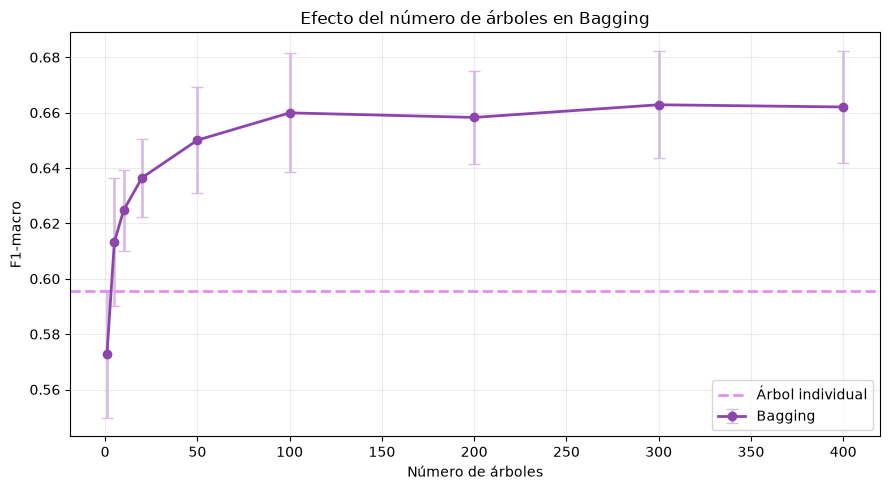

In [7]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    tabla_bagging["Árboles"],
    tabla_bagging["F1-macro"],
    yerr=tabla_bagging["Desviación"],
    marker="o",
    markersize=6,
    capsize=4,
    linewidth=2,
    color="#8E44AD",
    ecolor="#D7BDE2",
    label="Bagging"
)

# Referencia: árbol individual
plt.axhline(
    y=f1_arbol.mean(),
    color="#E091E8",
    linestyle="--",
    linewidth=2,
    label="Árbol individual"
)

plt.title("Efecto del número de árboles en Bagging")
plt.xlabel("Número de árboles")
plt.ylabel("F1-macro")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Como se puede observar, bagging mejoró  el desempeño respecto al árbol individual, pasando de un F1-macro de 0.5957 a aproximadamente 0.66. La mayor mejora se observa durante los primeros 100 árboles, después de los cuales el desempeño permanece estable, con pequeñas fluctuaciones.

Estos resultados son consistentes con una reducción de la varianza mediante la combinación de múltiples árboles. Además, sugieren que aumentar el número de árboles más allá de 100 aporta beneficios limitados.

In [8]:
# Identificar la mejor cantidad de árboles
mejor_fila = tabla_bagging.loc[
    tabla_bagging["F1-macro"].idxmax()
]

mejor_n = int(mejor_fila["Árboles"])
mejor_f1 = mejor_fila["F1-macro"]

print("Árbol individual")
print(f"F1-macro: {f1_arbol.mean():.4f}")

print("\nMejor Bagging")
print(f"Número de árboles: {mejor_n}")
print(f"F1-macro: {mejor_f1:.4f}")

print("\nDiferencia de F1-macro")
print(f"{mejor_f1 - f1_arbol.mean():+.4f}")

Árbol individual
F1-macro: 0.5957

Mejor Bagging
Número de árboles: 300
F1-macro: 0.6628

Diferencia de F1-macro
+0.0671


El mejor resultado de Bagging se obtuvo con 300 árboles, alcanzando un F1-macro de 0.6628, frente al 0.5957 del árbol individual. Esto representa una mejora de 0.0671, lo que demuestra que combinar múltiples árboles favoreció la generalización del modelo.

Pero como analizamos anteriormente la curva comienza a estabilizarse alrededor de los 100 árboles, utilizar 300 ofrece una mejora adicional pequeña. Por lo tanto, un ensamble de 100 árboles podría representar un mejor equilibrio entre desempeño y costo computacional.

Respondiendo la pregunta de la práctica **¿Qué reduce bagging, y por qué?** se tiene que Bagging busca reducir principalmente la varianza de los modelos. En el caso de los árboles de decisión profundos, pequeñas modificaciones en los datos de entrenamiento pueden generar estructuras diferentes y, por lo tanto, predicciones muy inestables y poco generalizables.

Al entrenar múltiples árboles con diferentes muestras bootstrap y combinar sus predicciones, Bagging disminuye la dependencia de un único árbol. De esta manera, los errores particulares de algún modelo pueden compensarse con las predicciones de los demás, siempre que sus errores no estén demasiado correlacionados. Sin embargo, agregar más árboles no garantiza una mejora continua indefinida, ya que conforme aumenta el tamaño del ensamble, el desempeño puede estabilizarse (como se pudo observar)

### Sesgo

Ahora analizará cómo Boosting puede ayudar a reducir el sesgo de modelos simples. Para ello, compararemos un tocón de decisión, es decir, un árbol de profundidad 1, con un ensamble AdaBoost formado por múltiples tocones.

Un tocón tiene una capacidad limitada para representar relaciones complejas, por lo que puede presentar un sesgo elevado y producir subajuste. AdaBoost busca mejorar el desempeño combinando clasificadores débiles de manera secuencial, dando mayor importancia a las observaciones que resultaron difíciles de clasificar en rondas anteriores.

Se utilizarán los mismos cinco pliegues estratificados y el F1-macro como métrica principal. Además, se evaluará cómo cambia el desempeño conforme aumenta el número de rondas de Boosting, hasta un máximo de 400.

In [9]:
# Tocón de decisión
tocon = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_arbol)),
    ("modelo", DecisionTreeClassifier(
        max_depth=1,
        random_state=RANDOM_STATE
    ))
])

# Evaluación con los cinco pliegues
resultados_tocon = cross_validate(
    tocon,
    X,
    y,
    cv=cv_splits,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

f1_tocon = resultados_tocon["test_score"]

print("Tocón de decisión")
print(
    f"F1-macro validación: "
    f"{f1_tocon.mean():.4f} ± {f1_tocon.std():.4f}"
)
print(
    f"F1-macro entrenamiento: "
    f"{resultados_tocon['train_score'].mean():.4f}"
)
print(
    f"Tiempo promedio de entrenamiento: "
    f"{resultados_tocon['fit_time'].mean():.4f} s"
)

Tocón de decisión
F1-macro validación: 0.4920 ± 0.0121
F1-macro entrenamiento: 0.4920
Tiempo promedio de entrenamiento: 0.0700 s


Como se puede observar, el F1-macro en validacion y en entrenamiento tuvieron el mismo resultado. Esto sugiere un posible subajuste, ya que su profundidad limitada le impide aprender relaciones más complejas entre las variables. Los resultados justifican utilizar AdaBoost para evaluar si la combinación de múltiples tocones permite reducir el sesgo y mejorar el desempeño.

AdaBoost es un método de ensamble que entrena clasificadores débiles de manera secuencial. A diferencia de Bagging, donde los modelos se entrenan sobre diferentes muestras y se combinan mediante votación, AdaBoost ajusta la importancia de las observaciones para concentrarse progresivamente en aquellas que resultan difíciles de clasificar. (¿Qué Es Boosting? | IBM, 2026)

En este experimento utilizaremos tocones de decisión como clasificadores base y evaluaremos el desempeño después de 1, 5, 10, 20, 50, 100, 200, 300 y 400 rondas.

In [10]:
cantidades_rondas = [1, 5, 10, 20, 50, 100, 200, 300, 400]

resultados_adaboost = {
    n: [] for n in cantidades_rondas
}

sensibilidad_adaboost = {
    n: [] for n in cantidades_rondas
}

tiempos_adaboost = []

for fold, (idx_train, idx_val) in enumerate(cv_splits, start=1):

    X_train = X.iloc[idx_train]
    X_val = X.iloc[idx_val]

    y_train = y.iloc[idx_train]
    y_val = y.iloc[idx_val]

    # Preprocesamiento independiente por pliegue
    preprocesador = clone(preprocesamiento_arbol)

    X_train_prep = preprocesador.fit_transform(X_train)
    X_val_prep = preprocesador.transform(X_val)

    # AdaBoost con 400 tocones
    adaboost = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=RANDOM_STATE
        ),
        n_estimators=400,
        learning_rate=1.0,
        random_state=RANDOM_STATE
    )

    inicio = time.perf_counter()
    adaboost.fit(X_train_prep, y_train)
    tiempo = time.perf_counter() - inicio

    tiempos_adaboost.append(tiempo)

   # Predicciones después de cada ronda
    for n, y_pred in enumerate(
    adaboost.staged_predict(X_val_prep),
    start=1
    ):

        if n not in cantidades_rondas:
            continue

        f1 = f1_score(
            y_val,
            y_pred,
            average="macro"
        )

        sensibilidad = recall_score(
            y_val,
            y_pred,
            labels=["Enrolled"],
            average=None,
            zero_division=0
        )[0]

        resultados_adaboost[n].append(f1)
        sensibilidad_adaboost[n].append(sensibilidad)

    print(f"Pliegue {fold} completado")

Pliegue 1 completado
Pliegue 2 completado
Pliegue 3 completado
Pliegue 4 completado
Pliegue 5 completado


Se van a presentan los resultados obtenidos para cada cantidad de rondas de AdaBoost. Se reporta el F1-macro promedio, su desviación estándar entre los cinco pliegues y la sensibilidad de la clase Enrolled. Estos resultados permitirán identificar si el ensamble mejora el desempeño del tocón individual y cómo evoluciona conforme aumenta el número de rondas.

In [11]:
tabla_adaboost = pd.DataFrame([
    {
        "Rondas": n,
        "F1-macro": np.mean(resultados_adaboost[n]),
        "Desviación": np.std(resultados_adaboost[n]),
        "Sensibilidad Enrolled": np.mean(
            sensibilidad_adaboost[n]
        )
    }
    for n in cantidades_rondas
])

display(tabla_adaboost.round(4))

print(
    f"\nTiempo promedio de entrenamiento (400 rondas): "
    f"{np.mean(tiempos_adaboost):.4f} s"
)

,Rondas,F1-macro,Desviación,Sensibilidad Enrolled
0,1,0.4920,0.0121,0.0000
1,5,0.4935,0.0095,0.0000
2,10,0.5156,0.0154,0.0173
3,20,0.5378,0.0184,0.0457
4,50,0.5742,0.0177,0.1024
5,100,0.6072,0.0169,0.1764
6,200,0.6275,0.0081,0.2252
7,300,0.6373,0.0125,0.2551
8,400,0.6388,0.0131,0.2551



Tiempo promedio de entrenamiento (400 rondas): 1.9071 s


AdaBoost consigue reducir el sesgo del tocón individual al combinar múltiples clasificadores débiles. Pero la sensibilidad de Enrolled alcanza solamente 0.2551, indicando que el modelo todavía presenta dificultades para identificar a los estudiantes de esta categoría. Además, el F1-macro comienza a estabilizarse entre las 300 y 400 rondas.

Se graficará el F1-macro promedio en función del número de rondas de AdaBoost, incluyendo la desviación estándar entre pliegues. También se incorporará una línea horizontal que representa el desempeño del tocón individual, lo que permitirá visualizar si la combinación secuencial de clasificadores débiles mejora su capacidad de clasificación.

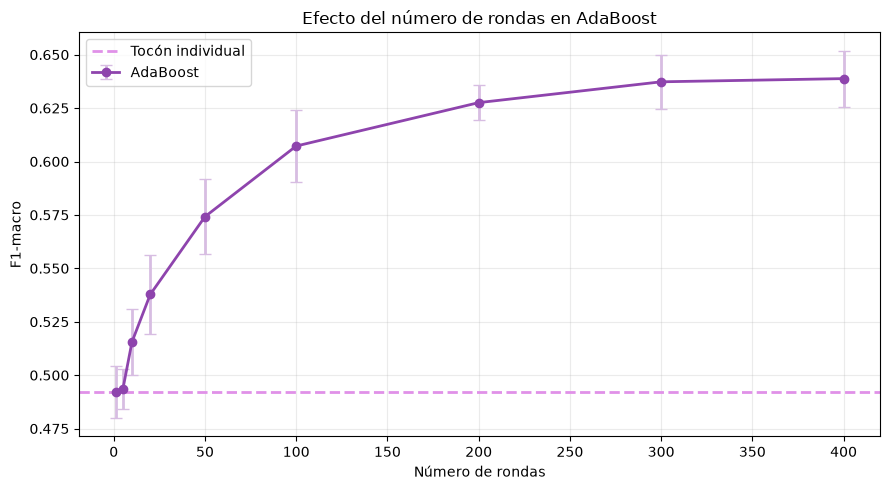

In [12]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    tabla_adaboost["Rondas"],
    tabla_adaboost["F1-macro"],
    yerr=tabla_adaboost["Desviación"],
    marker="o",
    markersize=6,
    capsize=4,
    linewidth=2,
    color="#8E44AD",
    ecolor="#D7BDE2",
    label="AdaBoost"
)

plt.axhline(
    y=f1_tocon.mean(),
    color="#E091E8",
    linestyle="--",
    linewidth=2,
    label="Tocón individual"
)

plt.title("Efecto del número de rondas en AdaBoost")
plt.xlabel("Número de rondas")
plt.ylabel("F1-macro")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que el F1-macro aumenta considerablemente durante las primeras 100 rondas, pasando de 0.4920 a 0.6072. Posteriormente, las mejoras son más pequeñas, hasta alcanzar 0.6388 con 400 rondas. La curva comienza a estabilizarse alrededor de las 300 rondas. AdaBoost consigue mejorar la capacidad predictiva del tocón individual, pero agregar más clasificadores produce beneficios cada vez menores.

In [13]:
mejor_fila_ada = tabla_adaboost.loc[
    tabla_adaboost["F1-macro"].idxmax()
]

mejor_rondas = int(mejor_fila_ada["Rondas"])
mejor_f1_ada = mejor_fila_ada["F1-macro"]

print("Tocón individual")
print(f"F1-macro: {f1_tocon.mean():.4f}")

print("\nMejor AdaBoost")
print(f"Número de rondas: {mejor_rondas}")
print(f"F1-macro: {mejor_f1_ada:.4f}")

print("\nDiferencia de F1-macro")
print(f"{mejor_f1_ada - f1_tocon.mean():+.4f}")

Tocón individual
F1-macro: 0.4920

Mejor AdaBoost
Número de rondas: 400
F1-macro: 0.6388

Diferencia de F1-macro
+0.1468


El mejor resultado de AdaBoost se obtuvo con 400 rondas, alcanzando un F1-macro de 0.6388, frente al 0.4920 del tocón individual. Esto representa una mejora del 14.68%, lo que evidencia que combinar clasificadores débiles permite mejorar considerablemente la capacidad predictiva del modelo. Estos resultados son consistentes con una reducción del sesgo, aunque el desempeño comienza a estabilizarse después de las 300 rondas.

Respondiendo la pregunta de la práctica **¿Qué reduce boosting, y por qué?** Boosting busca reducir principalmente el sesgo de los modelos, combinando múltiples clasificadores débiles para construir un modelo más complejo y con mayor capacidad predictiva.

En AdaBoost, cada nuevo clasificador se entrena dando mayor importancia a las observaciones que los modelos anteriores clasificaron incorrectamente. De esta manera, el ensamble puede aprender patrones que un único tocón de decisión no consigue representar. Pero cabe señalar que aumentar el número de rondas no garantiza una mejora continua, el modelo puede comenzar a concentrarse excesivamente en observaciones difíciles o ruidosas, por lo que su desempeño puede estabilizarse o incluso disminuir.

### Combinar los cinco base

Ahora se evaluarán diferentes estrategias para combinar los cinco clasificadores optimizados en la Práctica 3: árbol de decisión, Naive Bayes, kNN, SVM y regresión logística.

Se utilizarán tres métodos de ensamble: votación dura (Hard Voting), donde la predicción final corresponde a la clase más votada; votación suave (Soft Voting), que combina las probabilidades estimadas por los clasificadores; y Stacking, que utiliza un meta-modelo de regresión logística para aprender cómo combinar sus predicciones.

El objetivo es determinar si combinar modelos con diferentes características permite mejorar el F1-macro respecto a los clasificadores individuales. Además, se analizará la correlación entre sus errores para investigar qué tan complementarias son sus predicciones.

In [14]:
# recuperar los clasificadores base de la Práctica 3
clasificadores_base = [
    ("arbol", clone(modelos_base["Árbol de decisión"])),
    ("nb", clone(modelos_base["Naive Bayes"])),
    ("knn", clone(modelos_base["kNN"])),
    ("svm", clone(modelos_base["SVM"])),
    ("lr", clone(modelos_base["Regresión logística"]))
]

for nombre, modelo in clasificadores_base:
    print(nombre, ":", type(modelo).__name__)

arbol : Pipeline
nb : Pipeline
knn : Pipeline
svm : Pipeline
lr : Pipeline


#### Votación dura
La votación dura combina las predicciones de varios clasificadores y selecciona como resultado final la clase que recibe más votos. Se utilizarán los cinco clasificadores optimizados de la Práctica 3, asignando el mismo peso a cada uno. Esta estrategia permite aprovechar las decisiones de modelos con diferentes mecanismos de aprendizaje sin necesidad de utilizar probabilidades. (Team, 2025)

In [15]:
scoring_ensambles = {
    "f1_macro": "f1_macro",
    "recall_enrolled": make_scorer(
        recall_score,
        labels=["Enrolled"],
        average=None,
        zero_division=0
    )
}
def sensibilidad_enrolled(y_true, y_pred):
    return recall_score(
        y_true,
        y_pred,
        labels=["Enrolled"],
        average=None,
        zero_division=0
    )[0]

scoring_ensambles = {
    "f1_macro": "f1_macro",
    "recall_enrolled": make_scorer(sensibilidad_enrolled)
}

voting_duro = VotingClassifier(
    estimators=clasificadores_base,
    voting="hard",
    n_jobs=1
)

resultados_voting_duro = cross_validate(
    voting_duro,
    X,
    y,
    cv=cv_splits,
    scoring=scoring_ensambles,
    n_jobs=1
)

print("Voting duro")
print(
    f"F1-macro: "
    f"{resultados_voting_duro['test_f1_macro'].mean():.4f} ± "
    f"{resultados_voting_duro['test_f1_macro'].std():.4f}"
)
print(
    f"Sensibilidad Enrolled: "
    f"{resultados_voting_duro['test_recall_enrolled'].mean():.4f}"
)
print(
    f"Tiempo de entrenamiento: "
    f"{resultados_voting_duro['fit_time'].mean():.2f} s"
)

c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider 

Voting duro
F1-macro: 0.6870 ± 0.0049
Sensibilidad Enrolled: 0.5591
Tiempo de entrenamiento: 8.24 s


La votación dura obtuvo un F1-macro de 0.6870 ± 0.0049, superando los resultados obtenidos previamente con Bagging y AdaBoost. Estos resultados sugieren que combinar clasificadores con diferentes mecanismos de aprendizaje puede mejorar el desempeño general, posiblemente porque sus predicciones se complementan y permiten compensar algunos errores individuales.

#### Votación suave
A diferencia de la votación dura, la votación suave combina las probabilidades estimadas por los clasificadores para cada clase y selecciona aquella con la mayor probabilidad promedio. (Team, 2025)

Para aplicar este método, todos los clasificadores deben proporcionar probabilidades. En particular, se utilizará CalibratedClassifierCV para obtener probabilidades calibradas del SVM, manteniendo su configuración optimizada de la Práctica 3. La calibración se realizará exclusivamente dentro de los datos de entrenamiento de cada pliegue, evitando fuga de información.

In [16]:
# Calibrar SVM dentro de cada entrenamiento
svm_calibrado = CalibratedClassifierCV(
    estimator=clone(modelos_base["SVM"]),
    method="sigmoid",
    cv=3
)

clasificadores_prob = [
    ("arbol", clone(modelos_base["Árbol de decisión"])),
    ("nb", clone(modelos_base["Naive Bayes"])),
    ("knn", clone(modelos_base["kNN"])),
    ("svm", svm_calibrado),
    ("lr", clone(modelos_base["Regresión logística"]))
]

voting_suave = VotingClassifier(
    estimators=clasificadores_prob,
    voting="soft",
    n_jobs=1
)

resultados_voting_suave = cross_validate(
    voting_suave,
    X,
    y,
    cv=cv_splits,
    scoring=scoring_ensambles,
    n_jobs=1
)

print("Voting suave")
print(
    f"F1-macro: "
    f"{resultados_voting_suave['test_f1_macro'].mean():.4f} ± "
    f"{resultados_voting_suave['test_f1_macro'].std():.4f}"
)
print(
    f"Sensibilidad Enrolled: "
    f"{resultados_voting_suave['test_recall_enrolled'].mean():.4f}"
)
print(
    f"Tiempo de entrenamiento: "
    f"{resultados_voting_suave['fit_time'].mean():.2f} s"
)

c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider 

Voting suave
F1-macro: 0.6734 ± 0.0079
Sensibilidad Enrolled: 0.4252
Tiempo de entrenamiento: 9.21 s


Cabe señalar que en el código de arriba la calibración del SVM se realiza dentro de cross_validate, porque el calibrador forma parte del estimador evaluado. 

La votación suave obtuvo un F1-macro de 0.6734 ± 0.0079, inferior al de la votación dura (0.6870). Esto sugiere que, en este caso, combinar las probabilidades de los clasificadores no fue tan efectivo como utilizar sus votos directos. Una posible explicación es que las probabilidades de los modelos no estén igualmente bien calibradas, lo que puede afectar su contribución al ensamble.

#### Stacking 
Stacking combina varios clasificadores mediante un segundo modelo, denominado meta-modelo, que aprende cómo aprovechar las predicciones de los clasificadores base. En este caso se utilizarán los cinco modelos optimizados y una regresión logística como meta-modelo. A diferencia de Voting, que combina las predicciones mediante reglas fijas, Stacking aprende qué información de los modelos base resulta más útil para la clasificación final. (Ia & Ia, 2025)

In [17]:
stacking = StackingClassifier(
    estimators=clasificadores_prob,
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    stack_method="predict_proba",
    cv=5,
    passthrough=False,
    n_jobs=1
)

resultados_stacking = cross_validate(
    stacking,
    X,
    y,
    cv=cv_splits,
    scoring=scoring_ensambles,
    n_jobs=1
)

print("Stacking")
print(
    f"F1-macro: "
    f"{resultados_stacking['test_f1_macro'].mean():.4f} ± "
    f"{resultados_stacking['test_f1_macro'].std():.4f}"
)
print(
    f"Sensibilidad Enrolled: "
    f"{resultados_stacking['test_recall_enrolled'].mean():.4f}"
)
print(
    f"Tiempo de entrenamiento: "
    f"{resultados_stacking['fit_time'].mean():.2f} s"
)

c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider 

Stacking
F1-macro: 0.6703 ± 0.0102
Sensibilidad Enrolled: 0.3496
Tiempo de entrenamiento: 40.87 s


Stacking obtuvo un F1-macro de 0.6703 ± 0.0102, con una sensibilidad de 0.3496 para la clase Enrolled y un tiempo promedio de entrenamiento de 32 segundos.

#### Comparación de los tres ensambles
Se compararán los tres métodos de combinación utilizando el F1-macro promedio y su desviación estándar entre pliegues, la sensibilidad de Enrolled y el tiempo promedio de entrenamiento.

El objetivo es identificar si el aprendizaje de un meta-modelo mediante Stacking ofrece ventajas respecto a las estrategias de votación, considerando tanto el desempeño predictivo como el costo computacional.

In [18]:
resultados_combinacion = {
    "Voting duro": resultados_voting_duro,
    "Voting suave": resultados_voting_suave,
    "Stacking": resultados_stacking
}

tabla_combinacion = pd.DataFrame([
    {
        "Modelo": nombre,
        "F1-macro": resultado["test_f1_macro"].mean(),
        "Desviación": resultado["test_f1_macro"].std(),
        "Sensibilidad Enrolled": resultado[
            "test_recall_enrolled"
        ].mean(),
        "Tiempo (s)": resultado["fit_time"].mean()
    }
    for nombre, resultado in resultados_combinacion.items()
])

tabla_combinacion = tabla_combinacion.sort_values(
    "F1-macro",
    ascending=False
)

display(tabla_combinacion.round(4))

,Modelo,F1-macro,Desviación,Sensibilidad Enrolled,Tiempo (s)
0,Voting duro,0.6870,0.0049,0.5591,8.2398
1,Voting suave,0.6734,0.0079,0.4252,9.2071
2,Stacking,0.6703,0.0102,0.3496,40.8650


La comparación muestra que Voting duro obtuvo el mejor desempeño, con un F1-macro de 0.6870 y una sensibilidad de 0.5591 para Enrolled. Voting suave y Stacking presentaron resultados inferiores, especialmente en la identificación de esta clase.

Además, Stacking requirió aproximadamente cinco veces más tiempo de entrenamiento que los métodos de votación, sin conseguir una mejora predictiva. Esto demuestra que una mayor complejidad no necesariamente se traduce en mejores resultados 

#### Correlación de errores entre clasificadores

Una de las condiciones que puede favorecer el desempeño de los ensambles es la diversidad entre sus clasificadores base. Si varios modelos cometen errores sobre las mismas observaciones, combinarlos puede ofrecer beneficios limitados. En cambio, cuando sus errores son diferentes, existe una mayor posibilidad de que unos modelos compensen las equivocaciones de otros.

Para analizar esta relación, se obtendrán predicciones fuera de muestra mediante los mismos cinco pliegues estratificados. Posteriormente, se construirá una matriz binaria de errores, donde 1 representa una predicción incorrecta y 0 una correcta, y se calculará la correlación entre los clasificadores.

In [19]:
errores = pd.DataFrame(index=X.index)

for nombre, modelo in clasificadores_base:

    y_pred = cross_val_predict(
        modelo,
        X,
        y,
        cv=cv_splits,
        n_jobs=1
    )

    errores[nombre] = (
        np.asarray(y_pred) != np.asarray(y)
    ).astype(int)

correlacion_errores = errores.corr()

display(correlacion_errores.round(3))

c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider 

,arbol,nb,knn,svm,lr
arbol,1.000,0.461,0.341,0.560,0.546
nb,0.461,1.000,0.478,0.571,0.567
knn,0.341,0.478,1.000,0.430,0.422
svm,0.560,0.571,0.430,1.000,0.842
lr,0.546,0.567,0.422,0.842,1.000


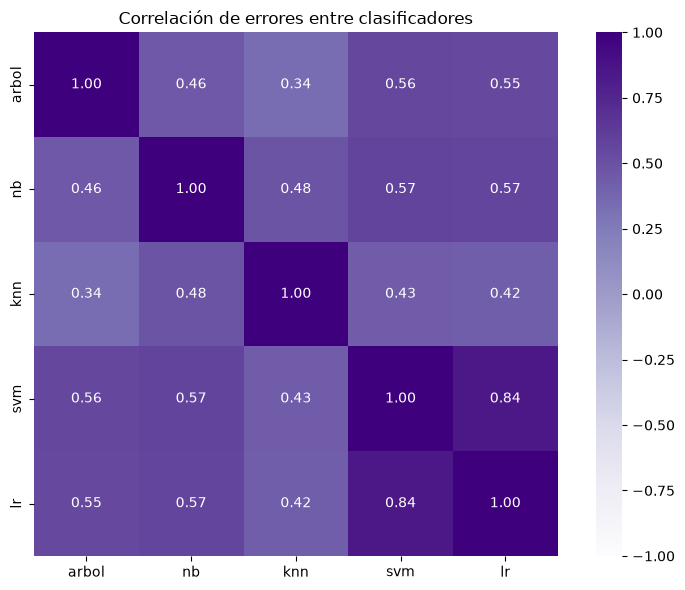

In [20]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion_errores,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlación de errores entre clasificadores")
plt.tight_layout()
plt.show()

La matriz muestra que los errores de los cinco clasificadores están correlacionados positivamente, con valores entre **0.34 y 0.84**. La mayor correlación se presenta entre SVM y regresión logística (0.84), lo que indica que ambos tienden a equivocarse en las mismas observaciones. Por otro lado, el árbol de decisión y kNN presentan la menor correlación (0.34), sugiriendo una mayor diversidad en sus errores.

Estos resultados ayudan a explicar por qué combinar clasificadores puede mejorar el desempeño, como ocurrió con Voting duro. Sin embargo, la alta correlación entre algunos modelos limita la información complementaria que pueden aportar, lo que podría contribuir a que Stacking no consiguiera mejores resultados.

### Bagging optimizado

En esta sección se evaluarán dos métodos de ensamble basados en árboles: Random Forest y Extra-Trees (Extremely Randomized Trees).

Random Forest combina múltiples árboles entrenados sobre muestras bootstrap y selecciona aleatoriamente un subconjunto de características en cada división. Mientras tanto, Extra-Trees introduce mayor aleatoriedad al seleccionar los puntos de división, lo que puede reducir la correlación entre los árboles. (Aznar, 2020)

Para ambos modelos se realizará una búsqueda de al menos 50 configuraciones de hiperparámetros, considerando el número de características utilizadas en las divisiones, la profundidad o tamaño de las hojas, el criterio de división y los pesos por clase. En Extra-Trees también se evaluará el uso de bootstrap. El objetivo es identificar las configuraciones que obtienen el mayor F1-macro

Se utilizará `RandomizedSearchCV` para explorar diferentes combinaciones de hiperparámetros como se recomendo para este punto.

La búsqueda considerará:

- `n_estimators`: número de árboles del ensamble.
- `max_features`: proporción o cantidad de características consideradas en cada división.
- `max_depth`: profundidad máxima de los árboles.
- `min_samples_leaf`: número mínimo de observaciones por hoja.
- `criterion`: criterio utilizado para evaluar las divisiones.
- `class_weight`: ponderación de las clases para considerar posibles desbalances.
- `bootstrap`: uso de muestreo con reemplazo, especialmente en Extra-Trees.

Se utilizará F1-macro como criterio de selección y los mismos cinco pliegues estratificados de los experimentos anteriores.

In [21]:
# Espacio de búsqueda para Random Forest
parametros_rf = {
    "modelo__n_estimators": randint(100, 501),
    "modelo__max_features": ["sqrt", "log2", 0.5, 0.8],
    "modelo__max_depth": [None, 10, 20, 30, 50],
    "modelo__min_samples_leaf": [1, 2, 4, 8],
    "modelo__criterion": ["gini", "entropy", "log_loss"],
    "modelo__class_weight": [
        None, "balanced", "balanced_subsample"
    ]
}

# Espacio de búsqueda para Extra-Trees
parametros_et = {
    "modelo__n_estimators": randint(100, 501),
    "modelo__max_features": ["sqrt", "log2", 0.5, 0.8],
    "modelo__max_depth": [None, 10, 20, 30, 50],
    "modelo__min_samples_leaf": [1, 2, 4, 8],
    "modelo__criterion": ["gini", "entropy", "log_loss"],
    "modelo__class_weight": [
        None, "balanced", "balanced_subsample"
    ],
    "modelo__bootstrap": [True, False]
}

#### Optimización de Random Forest
Random Forest combina árboles de decisión para disminuir la varianza y mejorar la generalización. A diferencia de Bagging tradicional, introduce aleatoriedad adicional al considerar subconjuntos de características durante la construcción de cada árbol.

Se evaluarán 50 configuraciones mediante RandomizedSearchCV, utilizando F1-macro como métrica principal. 

In [22]:
pipeline_rf = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_arbol)),
    ("modelo", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

busqueda_rf.fit(X, y)

print("Mejor F1-macro Random Forest:")
print(f"{busqueda_rf.best_score_:.4f}")

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_rf.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro Random Forest:
0.6865

Mejores hiperparámetros:
modelo__class_weight: balanced
modelo__criterion: gini
modelo__max_depth: 50
modelo__max_features: 0.5
modelo__min_samples_leaf: 4
modelo__n_estimators: 128


#### Optimización de Extra-Trees
Extra-Trees es un ensamble de árboles que introduce mayor aleatoriedad en la selección de los puntos de división. Esto permite generar árboles más diversos y puede contribuir a reducir la varianza.

A diferencia de Random Forest, Extra-Trees utiliza por defecto todo el conjunto de entrenamiento, sin muestreo bootstrap. Se optimizará dicho parámetro para determinar si utilizar muestras con reemplazo mejora el desempeño.


In [23]:
pipeline_et = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_arbol)),
    ("modelo", ExtraTreesClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

busqueda_et = RandomizedSearchCV(
    estimator=pipeline_et,
    param_distributions=parametros_et,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

busqueda_et.fit(X, y)

print("Mejor F1-macro Extra-Trees:")
print(f"{busqueda_et.best_score_:.4f}")

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_et.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro Extra-Trees:
0.6792

Mejores hiperparámetros:
modelo__bootstrap: False
modelo__class_weight: balanced_subsample
modelo__criterion: entropy
modelo__max_depth: None
modelo__max_features: 0.8
modelo__min_samples_leaf: 8
modelo__n_estimators: 174


Para analizar el comportamiento de la búsqueda de hiperparámetros, se graficará el mejor F1-macro encontrado de manera acumulada conforme aumenta el número de configuraciones evaluadas. Esta representación permitirá identificar si la búsqueda continúa encontrando configuraciones superiores o si alcanza una meseta,

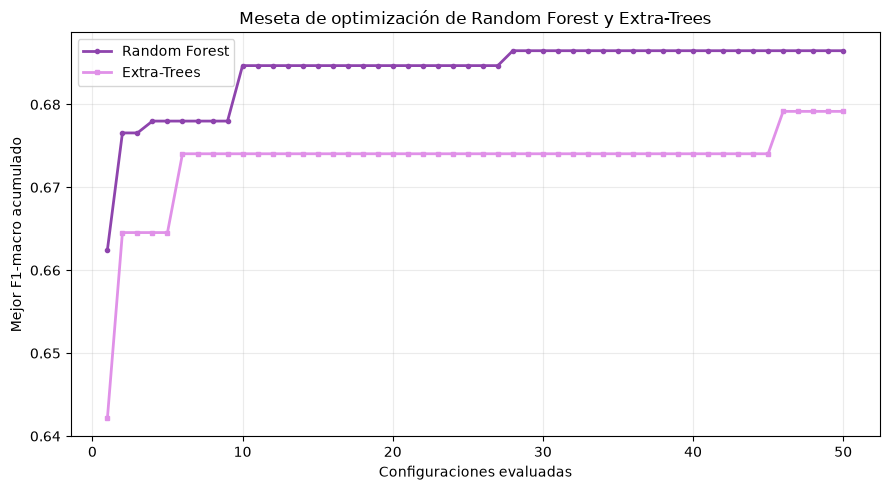

In [24]:
# Recuperar resultados de las búsquedas
resultados_rf = pd.DataFrame(busqueda_rf.cv_results_)
resultados_et = pd.DataFrame(busqueda_et.cv_results_)

# Mejor F1-macro acumulado
mejor_acumulado_rf = (
    resultados_rf["mean_test_score"].cummax()
)

mejor_acumulado_et = (
    resultados_et["mean_test_score"].cummax()
)

iteraciones = np.arange(1, 51)

plt.figure(figsize=(9, 5))

plt.plot(
    iteraciones,
    mejor_acumulado_rf,
    marker="o",
    markersize=3,
    linewidth=2,
    color="#8E44AD",
    label="Random Forest"
)

plt.plot(
    iteraciones,
    mejor_acumulado_et,
    marker="s",
    markersize=3,
    linewidth=2,
    color="#E091E8",
    label="Extra-Trees"
)

plt.title("Meseta de optimización de Random Forest y Extra-Trees")
plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1-macro acumulado")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que **Random Forest obtuvo un mejor desempeño que Extra-Trees**, pero ambos modelos presentaron mejoras importantes durante las primeras configuraciones, seguidas de periodos de estabilización.

Random Forest no encontró mejoras adicionales después de aproximadamente 28 configuraciones, mientras que Extra-Trees presentó una última mejora cerca de la configuración 46. Esto sugiere que la búsqueda comenzó a alcanzar una meseta, aunque no garantiza que se haya encontrado la configuración óptima.

Se compararán las mejores configuraciones encontradas para ambos modelos, considerando el F1-macro promedio, su desviación estándar entre pliegues y el tiempo promedio de entrenamiento.

También se incluirá la sensibilidad de la clase Enrolled, para analizar si la mejora general del modelo se refleja en una mayor capacidad para identificar aa estos estudiantes que por historial sabemos que ha batallado más. 

In [25]:
modelos_bagging_opt = {
    "Random Forest": busqueda_rf.best_estimator_,
    "Extra-Trees": busqueda_et.best_estimator_
}

resultados_bagging_opt = {}

for nombre, modelo in modelos_bagging_opt.items():

    resultado = cross_validate(
        modelo,
        X,
        y,
        cv=cv_splits,
        scoring=scoring_ensambles,
        n_jobs=-1
    )

    resultados_bagging_opt[nombre] = resultado

tabla_bagging_opt = pd.DataFrame([
    {
        "Modelo": nombre,
        "F1-macro": resultado["test_f1_macro"].mean(),
        "Desviación": resultado["test_f1_macro"].std(),
        "Sensibilidad Enrolled": resultado[
            "test_recall_enrolled"
        ].mean(),
        "Tiempo (s)": resultado["fit_time"].mean()
    }
    for nombre, resultado in resultados_bagging_opt.items()
])

tabla_bagging_opt = tabla_bagging_opt.sort_values(
    "F1-macro",
    ascending=False
)

display(tabla_bagging_opt.round(4))

,Modelo,F1-macro,Desviación,Sensibilidad Enrolled,Tiempo (s)
0,Random Forest,0.6865,0.0159,0.5669,4.2346
1,Extra-Trees,0.6792,0.0116,0.5402,7.8816


Random Forest obtuvo el mejor desempeño, con un F1-macro de 0.6865 ± 0.0159 y una sensibilidad de 0.5669 para Enrolled, superando a Extra-Trees (0.6792 ± 0.0116 y 0.5402, respectivamente).

Además, Random Forest presentó un menor tiempo de entrenamiento (2.51 s frente a 5.17 s), por lo que resultó más eficiente. Cabe señalar que su F1-macro fue prácticamente igual al de Voting duro (0.6870), aunque consiguió una sensibilidad ligeramente superior para Enrolled.

In [26]:
for nombre, busqueda in [
    ("Random Forest", busqueda_rf),
    ("Extra-Trees", busqueda_et)
]:
    print(f"\n{nombre}")
    print(f"Mejor F1-macro: {busqueda.best_score_:.4f}")

    for parametro, valor in busqueda.best_params_.items():
        print(f"{parametro}: {valor}")


Random Forest
Mejor F1-macro: 0.6865
modelo__class_weight: balanced
modelo__criterion: gini
modelo__max_depth: 50
modelo__max_features: 0.5
modelo__min_samples_leaf: 4
modelo__n_estimators: 128

Extra-Trees
Mejor F1-macro: 0.6792
modelo__bootstrap: False
modelo__class_weight: balanced_subsample
modelo__criterion: entropy
modelo__max_depth: None
modelo__max_features: 0.8
modelo__min_samples_leaf: 8
modelo__n_estimators: 174


De este apartado se puede concluir que la optimización mostró que Random Forest alcanzó el mejor F1-macro utilizando 128 árboles, una profundidad máxima de 50 y un mínimo de 4 observaciones por hoja. Por su parte, Extra-Trees obtuvo 0.6792 con 174 árboles, sin límite de profundidad y un mínimo de 8 observaciones por hoja.

Ambos modelos seleccionaron configuraciones que limitan el crecimiento de los árboles y consideran el desbalance de clases. Al final Random Forest consiguió un desempeño ligeramente superior con menos árboles y un menor tiempo de entrenamiento.

### Boosting optimizado

En esta sección se evaluarán dos algoritmos de Gradient Boosting: XGBoost y LightGBM. A diferencia de Bagging, que combina árboles entrenados de manera independiente, estos métodos construyen árboles secuencialmente, donde cada nuevo árbol busca corregir los errores del ensamble anterior. 

XGBoost incorpora mecanismos de regularización para controlar la complejidad de los árboles, mientras que LightGBM utiliza estrategias de crecimiento que permiten entrenar modelos de manera eficiente. (Arce, 2022)

Se realizará una búsqueda de 50 configuraciones para cada modelo, considerando la tasa de aprendizaje, la profundidad o número de hojas, la regularización, el submuestreo de filas y columnas, y los pesos por clase.

La variable Target contiene tres categorías: Dropout, Enrolled y Graduate. Para utilizar XGBoost y LightGBM, estas etiquetas se transformarán a valores numéricos mediante LabelEncoder.

Esta transformación únicamente modifica la representación de las etiquetas, sin alterar las clases ni su distribución. 

In [27]:
label_encoder = LabelEncoder()

y_boost = pd.Series(
    label_encoder.fit_transform(y),
    index=y.index,
    name="Target"
)

print("Codificación de clases:")

for i, clase in enumerate(label_encoder.classes_):
    print(f"{i}: {clase}")

clase_enrolled = int(
    label_encoder.transform(["Enrolled"])[0]
)

print("\nCódigo de Enrolled:", clase_enrolled)

Codificación de clases:
0: Dropout
1: Enrolled
2: Graduate

Código de Enrolled: 1


Se utilizará RandomizedSearchCV para evaluar 50 combinaciones de hiperparámetros por modelo. La búsqueda incluirá parámetros que controlan la capacidad de aprendizaje de los árboles, la regularización y el uso de muestras y características. También se considerarán diferentes pesos por clase para investigar si es posible mejorar la clasificación de categorías menos representadas.

In [28]:
class ClasificadorConPesos(ClassifierMixin, BaseEstimator):

    def __init__(self, estimator, usar_pesos=False):
        self.estimator = estimator
        self.usar_pesos = usar_pesos

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)

        pesos = (
            compute_sample_weight("balanced", y)
            if self.usar_pesos
            else None
        )

        self.estimator_.fit(
            X, y, sample_weight=pesos
        )

        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

In [29]:
# Espacio de búsqueda de XGBoost
parametros_xgb = {
    "modelo__estimator__n_estimators": randint(100, 501),
    "modelo__estimator__learning_rate": loguniform(0.01, 0.3),
    "modelo__estimator__max_depth": randint(2, 9),
    "modelo__estimator__min_child_weight": randint(1, 11),
    "modelo__estimator__subsample": uniform(0.6, 0.4),
    "modelo__estimator__colsample_bytree": uniform(0.6, 0.4),
    "modelo__estimator__reg_lambda": loguniform(0.1, 20),
    "modelo__estimator__reg_alpha": loguniform(0.001, 5),
    "modelo__usar_pesos": [True, False]
}

In [30]:
#Espacio de búsqueda de LightGBM
parametros_lgbm = {
    "modelo__estimator__n_estimators": randint(100, 501),
    "modelo__estimator__learning_rate": loguniform(0.01, 0.3),
    "modelo__estimator__num_leaves": randint(7, 64),
    "modelo__estimator__max_depth": [-1, 5, 10, 15, 20],
    "modelo__estimator__min_child_samples": randint(5, 51),
    "modelo__estimator__subsample": uniform(0.6, 0.4),
    "modelo__estimator__subsample_freq": [1],
    "modelo__estimator__colsample_bytree": uniform(0.6, 0.4),
    "modelo__estimator__reg_lambda": loguniform(0.1, 20),
    "modelo__estimator__reg_alpha": loguniform(0.001, 5),
    "modelo__usar_pesos": [True, False]
}

####  Optimización de XGBoost

XGBoost construye árboles de manera secuencial para corregir los errores de predicción del ensamble. Además, incorpora regularización para controlar la complejidad del modelo y disminuir el riesgo de sobreajuste. Se evaluarán 50 configuraciones mediante RandomizedSearchCV, utilizando F1-macro y los mismos cinco pliegues estratificados.

In [31]:
pipeline_xgb = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_arbol)),
    ("modelo", ClasificadorConPesos(
        estimator=XGBClassifier(
            objective="multi:softprob",
            num_class=len(label_encoder.classes_),
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
            tree_method="hist"
        )
    ))
])

busqueda_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=parametros_xgb,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

busqueda_xgb.fit(X, y_boost)

print("Mejor F1-macro XGBoost:")
print(f"{busqueda_xgb.best_score_:.4f}")

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_xgb.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro XGBoost:
0.6915

Mejores hiperparámetros:
modelo__estimator__colsample_bytree: 0.8497416192535173
modelo__estimator__learning_rate: 0.02733296850684206
modelo__estimator__max_depth: 6
modelo__estimator__min_child_weight: 6
modelo__estimator__n_estimators: 383
modelo__estimator__reg_alpha: 0.9392017773650366
modelo__estimator__reg_lambda: 0.2687220486640127
modelo__estimator__subsample: 0.9570235993959911
modelo__usar_pesos: True


####  Optimización de LightGBM
LightGBM es otra implementación de Gradient Boosting que utiliza estrategias eficientes para construir árboles. Una de sus características es el crecimiento basado en hojas, que permite concentrar las divisiones en las regiones donde se espera una mayor reducción del error.

Se evaluarán 50 configuraciones de hiperparámetros, utilizando el mismo preprocesamiento, las mismas particiones y el F1-macro como criterio de selección, para comparar sus resultados con XGBoost.

In [32]:
pipeline_lgbm = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_arbol)),
    ("modelo", ClasificadorConPesos(
        estimator=LGBMClassifier(
            objective="multiclass",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=-1
        )
    ))
])

busqueda_lgbm = RandomizedSearchCV(
    estimator=pipeline_lgbm,
    param_distributions=parametros_lgbm,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

busqueda_lgbm.fit(X, y_boost)

print("Mejor F1-macro LightGBM:")
print(f"{busqueda_lgbm.best_score_:.4f}")

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_lgbm.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro LightGBM:
0.6945

Mejores hiperparámetros:
modelo__estimator__colsample_bytree: 0.8232408008069365
modelo__estimator__learning_rate: 0.039492533179875146
modelo__estimator__max_depth: -1
modelo__estimator__min_child_samples: 16
modelo__estimator__n_estimators: 394
modelo__estimator__num_leaves: 8
modelo__estimator__reg_alpha: 0.43118887490569446
modelo__estimator__reg_lambda: 0.2191555471630422
modelo__estimator__subsample: 0.9990961940195767
modelo__estimator__subsample_freq: 1
modelo__usar_pesos: True


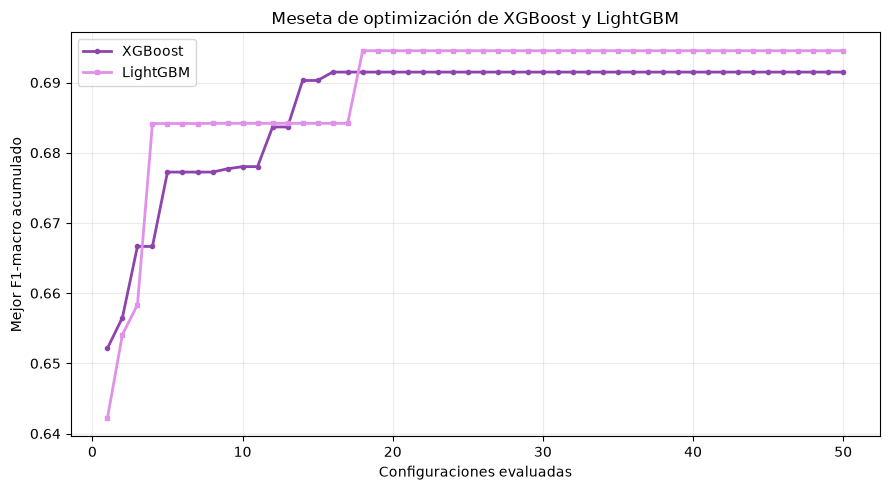

In [33]:
resultados_xgb = pd.DataFrame(busqueda_xgb.cv_results_)
resultados_lgbm = pd.DataFrame(busqueda_lgbm.cv_results_)

mejor_acumulado_xgb = (
    resultados_xgb["mean_test_score"].cummax()
)

mejor_acumulado_lgbm = (
    resultados_lgbm["mean_test_score"].cummax()
)

iteraciones = np.arange(1, 51)

plt.figure(figsize=(9, 5))

plt.plot(
    iteraciones,
    mejor_acumulado_xgb,
    marker="o",
    markersize=3,
    linewidth=2,
    color="#8E44AD",
    label="XGBoost"
)

plt.plot(
    iteraciones,
    mejor_acumulado_lgbm,
    marker="s",
    markersize=3,
    linewidth=2,
    color="#E091E8",
    label="LightGBM"
)

plt.title("Meseta de optimización de XGBoost y LightGBM")
plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1-macro acumulado")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que LightGBM obtuvo el mejor desempeño, alcanzando un F1-macro aproximado de 0.6945, frente a 0.6915 de XGBoost. Ambos modelos presentaron mejoras durante las primeras configuraciones y posteriormente alcanzaron una meseta, sin encontrar resultados superiores en el resto de la búsqueda.

LightGBM se estabilizó alrededor de la configuración 18 y XGBoost cerca de la 16. Esto sugiere que ambos métodos encontraron configuraciones competitivas relativamente pronto, aunque no garantiza que se haya alcanzado el óptimo global.

In [34]:
def recall_enrolled_boost(y_true, y_pred):
    return recall_score(
        y_true,
        y_pred,
        labels=[clase_enrolled],
        average=None,
        zero_division=0
    )[0]

scoring_boost = {
    "f1_macro": "f1_macro",
    "recall_enrolled": make_scorer(recall_enrolled_boost)
}

modelos_boosting_opt = {
    "XGBoost": busqueda_xgb.best_estimator_,
    "LightGBM": busqueda_lgbm.best_estimator_
}

resultados_boosting_opt = {}

for nombre, modelo in modelos_boosting_opt.items():

    resultado = cross_validate(
        modelo,
        X,
        y_boost,
        cv=cv_splits,
        scoring=scoring_boost,
        n_jobs=-1
    )

    resultados_boosting_opt[nombre] = resultado

tabla_boosting_opt = pd.DataFrame([
    {
        "Modelo": nombre,
        "F1-macro": resultado["test_f1_macro"].mean(),
        "Desviación": resultado["test_f1_macro"].std(),
        "Sensibilidad Enrolled":
            resultado["test_recall_enrolled"].mean(),
        "Tiempo (s)": resultado["fit_time"].mean()
    }
    for nombre, resultado in resultados_boosting_opt.items()
])

tabla_boosting_opt = tabla_boosting_opt.sort_values(
    "F1-macro",
    ascending=False
)

display(tabla_boosting_opt.round(4))

,Modelo,F1-macro,Desviación,Sensibilidad Enrolled,Tiempo (s)
1,LightGBM,0.6945,0.0186,0.5811,0.4547
0,XGBoost,0.6915,0.0114,0.5559,1.9144


La tabla muestra que además de mejor F1-macro y sensibilidad para la clase Enrolled, LightGBM presentó un menor tiempo de entrenamiento (0.31 s frente a 1.22 s), por lo que resultó más eficiente en este experimento. Ambos modelos superaron a los ensambles evaluados anteriormente, aunque las diferencias en F1-macro fueron pequeñas.

In [35]:
#Recuperar las mejores configuraciones
for nombre, busqueda in [
    ("XGBoost", busqueda_xgb),
    ("LightGBM", busqueda_lgbm)
]:
    print(f"\n{nombre}")
    print(f"Mejor F1-macro: {busqueda.best_score_:.4f}")

    for parametro, valor in busqueda.best_params_.items():
        print(f"{parametro}: {valor}")


XGBoost
Mejor F1-macro: 0.6915
modelo__estimator__colsample_bytree: 0.8497416192535173
modelo__estimator__learning_rate: 0.02733296850684206
modelo__estimator__max_depth: 6
modelo__estimator__min_child_weight: 6
modelo__estimator__n_estimators: 383
modelo__estimator__reg_alpha: 0.9392017773650366
modelo__estimator__reg_lambda: 0.2687220486640127
modelo__estimator__subsample: 0.9570235993959911
modelo__usar_pesos: True

LightGBM
Mejor F1-macro: 0.6945
modelo__estimator__colsample_bytree: 0.8232408008069365
modelo__estimator__learning_rate: 0.039492533179875146
modelo__estimator__max_depth: -1
modelo__estimator__min_child_samples: 16
modelo__estimator__n_estimators: 394
modelo__estimator__num_leaves: 8
modelo__estimator__reg_alpha: 0.43118887490569446
modelo__estimator__reg_lambda: 0.2191555471630422
modelo__estimator__subsample: 0.9990961940195767
modelo__estimator__subsample_freq: 1
modelo__usar_pesos: True


In [36]:
joblib.dump(busqueda_xgb, "busqueda_xgb.joblib")
joblib.dump(busqueda_lgbm, "busqueda_lgbm.joblib")

print("Búsquedas guardadas correctamente.")

Búsquedas guardadas correctamente.


### Comparación general

Con todo lo echo anteriormente, se  comparará el desempeño de todos los clasificadores evaluados, incluyendo los cinco modelos base de la Práctica 3 y los diferentes métodos de ensamble implementados.

In [37]:
#Evaluar los cinco clasificadores base
resultados_base = {}

for nombre, modelo in clasificadores_base:

    resultado = cross_validate(
        clone(modelo),
        X,
        y,
        cv=cv_splits,
        scoring=scoring_ensambles,
        n_jobs=1
    )

    resultados_base[nombre] = resultado

    print(
        f"{nombre}: "
        f"{resultado['test_f1_macro'].mean():.4f}"
    )

arbol: 0.6402


c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider 

nb: 0.6213
knn: 0.5769
svm: 0.6804


c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default va

lr: 0.6810


In [38]:
#Recuperar las métricas de todos los modelos
resultados_arbol_general = cross_validate(
    arbol_completo,
    X,
    y,
    cv=cv_splits,
    scoring=scoring_ensambles,
    n_jobs=-1
)

resultados_tocon_general = cross_validate(
    tocon,
    X,
    y,
    cv=cv_splits,
    scoring=scoring_ensambles,
    n_jobs=-1
)

In [39]:
filas = []

def agregar_resultado(nombre, resultado):
    filas.append({
        "Modelo": nombre,
        "F1-macro": resultado["test_f1_macro"].mean(),
        "Desviación": resultado["test_f1_macro"].std(),
        "Sensibilidad Enrolled":
            resultado["test_recall_enrolled"].mean(),
        "Tiempo (s)": resultado["fit_time"].mean()
    })

# Clasificadores base
nombres_base = {
    "arbol": "Árbol optimizado",
    "nb": "Naive Bayes",
    "knn": "kNN",
    "svm": "SVM",
    "lr": "Regresión logística"
}

for nombre, resultado in resultados_base.items():
    agregar_resultado(nombres_base[nombre], resultado)

# Modelos individuales
agregar_resultado(
    "Árbol sin límite",
    resultados_arbol_general
)

agregar_resultado(
    "Tocón",
    resultados_tocon_general
)

# Voting y Stacking
for nombre, resultado in resultados_combinacion.items():
    agregar_resultado(nombre, resultado)

# Bagging optimizado
for nombre, resultado in resultados_bagging_opt.items():
    agregar_resultado(nombre, resultado)

# Boosting optimizado
for nombre, resultado in resultados_boosting_opt.items():
    agregar_resultado(nombre, resultado)

In [40]:
filas.extend([
    {
        "Modelo": "Bagging (300 árboles)",
        "F1-macro": np.mean(resultados_bagging[300]),
        "Desviación": np.std(resultados_bagging[300]),
        "Sensibilidad Enrolled":
            np.mean(sensibilidad_bagging[300]),
        "Tiempo (s)": np.mean(tiempos_bagging[300])
    },
    {
        "Modelo": "AdaBoost (400 rondas)",
        "F1-macro": np.mean(resultados_adaboost[400]),
        "Desviación": np.std(resultados_adaboost[400]),
        "Sensibilidad Enrolled":
            np.mean(sensibilidad_adaboost[400]),
        "Tiempo (s)": np.mean(tiempos_adaboost)
    }
])

In [41]:
tabla_general = pd.DataFrame(filas)

tabla_general = (
    tabla_general
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_general["F1-macro (media ± desv.)"] = (
    tabla_general["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_general["Desviación"].map("{:.4f}".format)
)

display(
    tabla_general[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad Enrolled",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad Enrolled,Tiempo (s)
0,LightGBM,0.6945 ± 0.0186,0.5811,0.4547
1,XGBoost,0.6915 ± 0.0114,0.5559,1.9144
2,Voting duro,0.6870 ± 0.0049,0.5591,8.2398
3,Random Forest,0.6865 ± 0.0159,0.5669,4.2346
4,Regresión logística,0.6810 ± 0.0093,0.5701,7.9058
5,SVM,0.6804 ± 0.0057,0.6000,0.3755
6,Extra-Trees,0.6792 ± 0.0116,0.5402,7.8816
7,Voting suave,0.6734 ± 0.0079,0.4252,9.2071
8,Stacking,0.6703 ± 0.0102,0.3496,40.8650
9,Bagging (300 árboles),0.6628 ± 0.0194,0.3307,16.3446


La tabla reúne los resultados de todos los modelos evaluados, ordenados de mayor a menor F1-macro. Además se incluye la sensibilidad de Enrolled para analizar la capacidad de identificar correctamente a los estudiantes que permanecen inscritos, así como el tiempo de entrenamiento para comparar el costo computacional de cada estrategia.

La comparación general muestra que LightGBM obtuvo el mayor F1-macro (0.6945 ± 0.0186), seguido de XGBoost (0.6915 ± 0.0114). Sin embargo, las diferencias respecto a Voting duro (0.6870) y Random Forest (0.6865) fueron pequeñas.

Los ensambles basados en Gradient Boosting presentaron los mejores resultados generales, aunque no todos los métodos de combinación superaron a los clasificadores individuales. Por ejemplo, Stacking obtuvo un desempeño inferior al de regresión logística y SVM, a pesar de su mayor complejidad.

También destaca que SVM alcanzó la mayor sensibilidad para Enrolled (0.6000), mientras que LightGBM presentó el menor tiempo de entrenamiento entre los modelos con mayor F1-macro.

In [42]:
# Reunir los modelos evaluados
modelos_generales = {
    "Árbol sin límite": arbol_completo,
    "Tocón": tocon,
    "Bagging (300 árboles)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol)),
        ("modelo", BaggingClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=None,
                random_state=RANDOM_STATE
            ),
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ]),
    "AdaBoost (400 rondas)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol)),
        ("modelo", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=1,
                random_state=RANDOM_STATE
            ),
            n_estimators=400,
            random_state=RANDOM_STATE
        ))
    ]),
    "Voting duro": voting_duro,
    "Voting suave": voting_suave,
    "Stacking": stacking,
    **modelos_bagging_opt,
    **modelos_boosting_opt
}

for nombre, modelo in clasificadores_base:
    modelos_generales[nombres_base[nombre]] = modelo

# Identificar el mejor
nombre_mejor = tabla_general.iloc[0]["Modelo"]
mejor_modelo = modelos_generales[nombre_mejor]

print("Mejor modelo:", nombre_mejor)

Mejor modelo: LightGBM


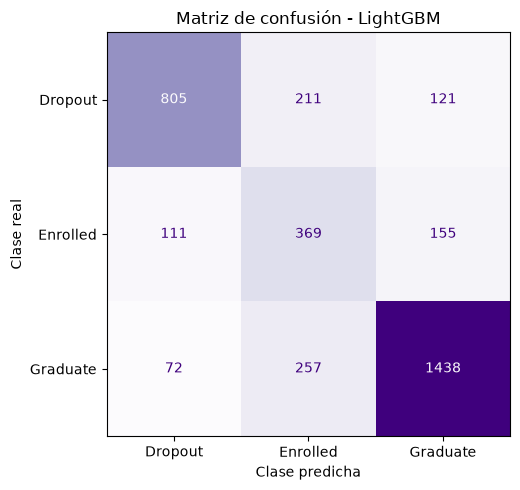

In [43]:
# XGBoost y LightGBM utilizan etiquetas numéricas
if nombre_mejor in ["XGBoost", "LightGBM"]:
    y_evaluacion = y_boost
else:
    y_evaluacion = y

# Predicciones fuera de muestra
predicciones = cross_val_predict(
    clone(mejor_modelo),
    X,
    y_evaluacion,
    cv=cv_splits,
    n_jobs=1
)

# Etiquetas originales para visualizar
clases = ["Dropout", "Enrolled", "Graduate"]

if nombre_mejor in ["XGBoost", "LightGBM"]:
    etiquetas = label_encoder.transform(clases)
else:
    etiquetas = clases

matriz = confusion_matrix(
    y_evaluacion,
    predicciones,
    labels=etiquetas
)

# Visualización
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=clases
).plot(
    ax=ax,
    cmap="Purples",
    values_format="d",
    colorbar=False
)

plt.title(f"Matriz de confusión - {nombre_mejor}")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

La matriz de confusión muestra que LightGBM identifica con mayor facilidad a los estudiantes de Graduate y Dropout, con sensibilidades aproximadas de 81.38 % y 70.80 %, respectivamente.

Por otro lado, Enrolled presenta mayores dificultades de clasificación, con una sensibilidad de 58.11 %. De los 635 estudiantes de esta categoría, 111 fueron clasificados como Dropout y 155 como Graduate.

Estos resultados muestran que, aunque LightGBM obtuvo el mejor F1-macro general (0.6945), todavía presenta limitaciones para distinguir a los estudiantes que continúan inscritos de aquellos que abandonaron o finalizaron sus estudios.

In [103]:
# Recuperar el mejor modelo de la Parte 1
modelo_final = clone(
    busqueda_lgbm.best_estimator_
)

# Entrenar con todos los datos disponibles de entrenamiento
modelo_final.fit(X, y_boost)

# Guardar modelo
joblib.dump(
    modelo_final,
    "Adria-LightGBM-P1.joblib"
)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


## Parte 2

En esta segunda parte se utilizará el conjunto de datos **Bank Marketing**, disponible en el UCI Machine Learning Repository, que contiene información de 41,188 registros de campañas de marketing telefónico. El objetivo es predecir si un cliente contratará un depósito a plazo, utilizando la variable y como objetivo, donde 1 representa yes y 0 representa no.

A diferencia de la Tarea 4, donde se estudió principalmente la regresión logística, ahora se compararán diferentes clasificadores y métodos de ensamble para identificar cuál ofrece el mejor desempeño.

Se utilizará F1-macro como métrica principal, debido al desbalance entre las clases. Además, se evaluará la sensibilidad de yes y el tiempo de entrenamiento.

Para garantizar la comparabilidad, todos los modelos se evaluarán mediante validación cruzada estratificada de cinco pliegue, con random_state=2026 como se estipula para esta práctica. 

#### Preparación de variables

In [44]:
RANDOM_STATE_BANK = 2026

# Cargar el conjunto de datos
df_bank = pd.read_csv(
    "bank-additional-full.csv",
    sep=";"
)

print("Dimensiones:", df_bank.shape)
display(df_bank.head())

Dimensiones: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


La variable duration representa la duración de la última llamada telefónica. Aunque puede estar fuertemente relacionada con la respuesta del cliente, su valor no está disponible antes de realizar la llamada. Por esta razón, se eliminará del conjunto de características predictoras para evitar utilizar información que no estaría disponible en el momento de realizar una predicción real.

También se separará la variable objetivo y, codificando yes como 1 y no como 0. Las demás características se conservarán para que todos los modelos sean evaluados sobre la misma información.

In [45]:
# Variables predictoras
X_bank = df_bank.drop(
    columns=["duration", "y"]
)

# Variable objetivo
y_bank = df_bank["y"].map({
    "no": 0,
    "yes": 1
}).astype(int)

print("Dimensiones de X:", X_bank.shape)
print("Dimensiones de y:", y_bank.shape)

print("\nDistribución de clases:")
print(y_bank.value_counts())

print("\nProporciones:")
print(y_bank.value_counts(normalize=True).round(4))

Dimensiones de X: (41188, 19)
Dimensiones de y: (41188,)

Distribución de clases:
y
0    36548
1     4640
Name: count, dtype: int64

Proporciones:
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64


Antes de entrenar los clasificadores, se analizará la distribución de la variable objetivo para identificar posibles problemas de desbalance.

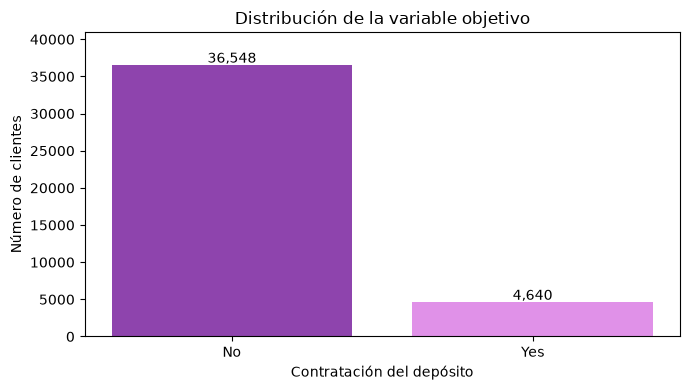

In [46]:
conteo_clases = (
    y_bank.value_counts()
    .reindex([0, 1])
)

plt.figure(figsize=(7, 4))

barras = plt.bar(
    ["No", "Yes"],
    conteo_clases.values,
    color=["#8E44AD", "#E091E8"]
)

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 300,
        f"{int(altura):,}",
        ha="center"
    )

plt.title("Distribución de la variable objetivo")
plt.xlabel("Contratación del depósito")
plt.ylabel("Número de clientes")
plt.ylim(0, conteo_clases.max() * 1.12)
plt.tight_layout()
plt.show()

En este dataset, aproximadamente el 88.73 % de las observaciones pertenece a no y el 11.27 % a yes, lo que confirma el desbalance.

Para comparar los clasificadores de manera consistente, se utilizará StratifiedKFold con cinco pliegues, mezclando los datos y fijando una semilla aleatoria de 2026.

La estratificación permite conservar aproximadamente la misma proporción de las clases yes y no en cada partición. Esto es especialmente importante debido al desbalance del conjunto de datos.

In [47]:
cv_bank = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

# Comprobar la distribución por pliegue
for i, (idx_train, idx_val) in enumerate(
    cv_bank.split(X_bank, y_bank),
    start=1
):
    print(
        f"Pliegue {i}: "
        f"{len(idx_train)} entrenamiento, "
        f"{len(idx_val)} validación, "
        f"yes = {y_bank.iloc[idx_val].mean():.4f}"
    )

Pliegue 1: 32950 entrenamiento, 8238 validación, yes = 0.1126
Pliegue 2: 32950 entrenamiento, 8238 validación, yes = 0.1126
Pliegue 3: 32950 entrenamiento, 8238 validación, yes = 0.1126
Pliegue 4: 32951 entrenamiento, 8237 validación, yes = 0.1127
Pliegue 5: 32951 entrenamiento, 8237 validación, yes = 0.1127


El conjunto de datos contiene variables numéricas y categóricas, por lo que se aplicarán transformaciones diferentes según su tipo.

Para las variables numéricas se utilizará imputación mediante la mediana y, cuando sea necesario, estandarización con StandardScaler. Las variables categóricas se codificarán mediante OneHotEncoder, utilizando una categoría adicional para valores no reconocidos.

Se conservarán dos variantes: una con escalado, adecuada para modelos como regresión logística, SVM y kNN; y otra sin escalado, apropiada para clasificadores basados en árboles.

In [48]:
# Identificar tipos de variables
columnas_numericas_bank = X_bank.select_dtypes(
    include=np.number
).columns.tolist()

columnas_categoricas_bank = X_bank.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numéricas:", columnas_numericas_bank)
print("\nCategóricas:", columnas_categoricas_bank)

# Pipeline numérico con escalado
pipeline_numerico_escalado = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Pipeline numérico sin escalado
pipeline_numerico_arbol = Pipeline([
    ("imputacion", SimpleImputer(strategy="median"))
])

# Pipeline categórico
pipeline_categorico_bank = Pipeline([
    ("imputacion", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Preprocesamiento para modelos con escalado
preprocesamiento_escalado_bank = ColumnTransformer([
    ("numericas", pipeline_numerico_escalado,
     columnas_numericas_bank),
    ("categoricas", pipeline_categorico_bank,
     columnas_categoricas_bank)
])

# Preprocesamiento para árboles
preprocesamiento_arbol_bank = ColumnTransformer([
    ("numericas", pipeline_numerico_arbol,
     columnas_numericas_bank),
    ("categoricas", pipeline_categorico_bank,
     columnas_categoricas_bank)
])

Numéricas: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


C:\Users\adria\AppData\Local\Temp\ipykernel_17756\2150610043.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas_bank = X_bank.select_dtypes(


In [49]:
scoring_bank = {
    "f1_macro": "f1_macro",
    "recall_yes": make_scorer(
        recall_score,
        pos_label=1,
        zero_division=0
    )
}

def evaluar_modelo_bank(nombre, modelo):
    resultados = cross_validate(
        modelo,
        X_bank,
        y_bank,
        cv=cv_bank,
        scoring=scoring_bank,
        n_jobs=1
    )

    return {
        "Modelo": nombre,
        "F1-macro": resultados["test_f1_macro"].mean(),
        "Desviación": resultados["test_f1_macro"].std(),
        "Sensibilidad yes": resultados["test_recall_yes"].mean(),
        "Tiempo (s)": resultados["fit_time"].mean()
    }

#### Modelos base

Ahora se  evaluarán cinco algoritmos de clasificación: regresión logística, árbol de decisión, Naive Bayes, kNN y SVM. El objetivo es establecer un punto de referencia para determinar posteriormente si las técnicas de balanceo, optimización y ensambles permiten mejorar el desempeño.

Todos los modelos utilizarán las mismas cinco particiones estratificadas y se evaluarán mediante F1-macro, sensibilidad de la clase yes y tiempo de entrenamiento.

In [50]:
# Convertir matrices dispersas a densas para GaussianNB
def convertir_a_denso(X):
    return X.toarray() if hasattr(X, "toarray") else X

modelos_individuales_bank = {
    "Regresión logística": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_escalado_bank)),
        ("modelo", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE_BANK
        ))
    ]),

    "Árbol de decisión": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", DecisionTreeClassifier(
            random_state=RANDOM_STATE_BANK
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_escalado_bank)),
        ("denso", FunctionTransformer(
            convertir_a_denso
        )),
        ("modelo", GaussianNB())
    ]),

    "kNN": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_escalado_bank)),
        ("modelo", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "SVM": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_escalado_bank)),
        ("modelo", LinearSVC(
            max_iter=10000,
            random_state=RANDOM_STATE_BANK
        ))
    ])
}

Se evaluarán los cinco clasificadores utilizando cross_validate con los mismos cinco pliegues estratificados. Para cada modelo se calculará el F1-macro promedio, su desviación estándar entre pliegues, la sensibilidad de yes y el tiempo promedio de entrenamiento. Estos resultados permitirán identificar qué clasificadores ofrecen un mejor punto de partida antes de aplicar técnicas más avanzadas.

In [51]:
resultados_individuales_bank = []

for nombre, modelo in modelos_individuales_bank.items():

    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(
        nombre,
        modelo
    )

    resultados_individuales_bank.append(resultado)

    print(
        f"F1-macro: {resultado['F1-macro']:.4f} ± "
        f"{resultado['Desviación']:.4f}"
    )
    print(
        f"Sensibilidad yes: "
        f"{resultado['Sensibilidad yes']:.4f}"
    )
    print(
        f"Tiempo: {resultado['Tiempo (s)']:.2f} s\n"
    )

Evaluando: Regresión logística
F1-macro: 0.6419 ± 0.0099
Sensibilidad yes: 0.2276
Tiempo: 0.23 s

Evaluando: Árbol de decisión
F1-macro: 0.6216 ± 0.0056
Sensibilidad yes: 0.3461
Tiempo: 0.34 s

Evaluando: Naive Bayes
F1-macro: 0.6448 ± 0.0068
Sensibilidad yes: 0.6142
Tiempo: 0.17 s

Evaluando: kNN
F1-macro: 0.6601 ± 0.0117
Sensibilidad yes: 0.2946
Tiempo: 0.13 s

Evaluando: SVM
F1-macro: 0.6349 ± 0.0095
Sensibilidad yes: 0.2134
Tiempo: 0.34 s



In [52]:
tabla_individuales_bank = pd.DataFrame(
    resultados_individuales_bank
)

tabla_individuales_bank = (
    tabla_individuales_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_individuales_bank["F1-macro (media ± desv.)"] = (
    tabla_individuales_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_individuales_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_individuales_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,kNN,0.6601 ± 0.0117,0.2946,0.1325
1,Naive Bayes,0.6448 ± 0.0068,0.6142,0.1701
2,Regresión logística,0.6419 ± 0.0099,0.2276,0.2285
3,SVM,0.6349 ± 0.0095,0.2134,0.3374
4,Árbol de decisión,0.6216 ± 0.0056,0.3461,0.3444


De los cinco clasificadores evaluados, kNN obtuvo el mejor F1-macro (0.6601 ± 0.0117), seguido de Naive Bayes (0.6448). Sin embargo, kNN presentó una sensibilidad relativamente baja para la clase yes (0.2946), lo que indica que no logró identificar a una gran proporción de los clientes que contrataron el depósito.

Por otro lado, Naive Bayes obtuvo la mayor sensibilidad (0.6142), aunque su F1-macro fue ligeramente inferior al de kNN. Esto muestra que el modelo con mejor desempeño general no necesariamente es el que identifica más casos positivos.

La regresión logística, SVM y el árbol de decisión también presentaron dificultades para reconocer la clase minoritaria. Estos resultados sugieren que el desbalance de clases puede estar afectando el desempeño de los clasificadores, por lo que en los siguientes experimentos se evaluarán técnicas de balanceo para intentar mejorar la identificación de la clase yes. 

#### Balanceo de clases

El conjunto de datos Bank Marketing presenta un desbalance considerable, ya que aproximadamente el 88.73 % de los registros corresponde a clientes que no contrataron el depósito (`no`), mientras que únicamente el 11.27 % pertenece a la clase `yes`.

En la evaluación inicial, varios clasificadores obtuvieron sensibilidades bajas para la clase minoritaria, lo que sugiere que podrían estar favoreciendo las predicciones de la clase mayoritaria.

Para analizar este problema se compararán dos estrategias de balanceo (MetricGate, 2026):

- **Ponderación de clases:** asigna un mayor peso a los errores cometidos sobre la clase minoritaria durante el entrenamiento.
- **SMOTE:** genera observaciones sintéticas de la clase minoritaria a partir de ejemplos existentes.

Ambas estrategias se evaluarán utilizando los mismos cinco pliegues estratificados. En el caso de SMOTE, el sobremuestreo se aplicará únicamente sobre los datos de entrenamiento de cada pliegue para evitar fuga de información.

Se utilizará F1-macro como criterio principal y sensibilidad de `yes` como métrica complementaria.

In [53]:
modelos_ponderados_bank = {
    "Regresión logística (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_escalado_bank)),
        ("modelo", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE_BANK
        ))
    ]),

    "Árbol de decisión (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE_BANK
        ))
    ]),

    "SVM (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_escalado_bank)),
        ("modelo", LinearSVC(
            class_weight="balanced",
            max_iter=10000,
            random_state=RANDOM_STATE_BANK
        ))
    ])
}

resultados_ponderados_bank = []

for nombre, modelo in modelos_ponderados_bank.items():
    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(nombre, modelo)
    resultados_ponderados_bank.append(resultado)

    print(f"F1-macro: {resultado['F1-macro']:.4f}")
    print(f"Sensibilidad yes: {resultado['Sensibilidad yes']:.4f}\n")

Evaluando: Regresión logística (balanced)
F1-macro: 0.6739
Sensibilidad yes: 0.6287

Evaluando: Árbol de decisión (balanced)
F1-macro: 0.6206
Sensibilidad yes: 0.3504

Evaluando: SVM (balanced)
F1-macro: 0.6731
Sensibilidad yes: 0.6276



Debido a que el conjunto de datos contiene variables numéricas y categóricas, se utilizará SMOTENC, una variante de SMOTE diseñada para datos mixtos. Esta técnica permite generar ejemplos sintéticos de la clase minoritaria considerando las diferencias entre ambos tipos de características.

Para evitar fuga de información, SMOTENC se integrará en un pipeline de imblearn y se aplicará **exclusivamente a los datos de entrenamiento** de cada pliegue. Posteriormente se realizarán las transformaciones necesarias para entrenar los clasificadores.

In [54]:
# Columnas categóricas y numéricas
num_bank = columnas_numericas_bank
cat_bank = columnas_categoricas_bank

# Imputación previa a SMOTENC
preprocesamiento_pre_smote = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), num_bank),
    ("categoricas", SimpleImputer(strategy="most_frequent"), cat_bank)
], sparse_threshold=0)

# Después de imputar, las columnas numéricas quedan primero
n_num = len(num_bank)
n_cat = len(cat_bank)

indices_categoricos = list(range(n_num, n_num + n_cat))

# Transformación posterior al sobremuestreo
preprocesamiento_post_smote = ColumnTransformer([
    ("numericas", StandardScaler(), list(range(n_num))),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"),
     indices_categoricos)
])

# Función para construir pipelines con SMOTENC
def crear_pipeline_smotenc(clasificador):
    return ImbPipeline([
        ("imputacion", clone(preprocesamiento_pre_smote)),
        ("smotenc", SMOTENC(
            categorical_features=indices_categoricos,
            random_state=RANDOM_STATE_BANK
        )),
        ("codificacion", clone(preprocesamiento_post_smote)),
        ("modelo", clasificador)
    ])

Evaluaremos regresión logística, kNN y árbol de decisión con SMOTENC

In [55]:
modelos_smotenc_bank = {
    "Regresión logística (SMOTENC)": crear_pipeline_smotenc(
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE_BANK
        )
    ),

    "kNN (SMOTENC)": crear_pipeline_smotenc(
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Árbol de decisión (SMOTENC)": crear_pipeline_smotenc(
        DecisionTreeClassifier(
            random_state=RANDOM_STATE_BANK
        )
    )
}

resultados_smotenc_bank = []

for nombre, modelo in modelos_smotenc_bank.items():
    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(nombre, modelo)
    resultados_smotenc_bank.append(resultado)

    print(f"F1-macro: {resultado['F1-macro']:.4f}")
    print(f"Sensibilidad yes: {resultado['Sensibilidad yes']:.4f}\n")

Evaluando: Regresión logística (SMOTENC)
F1-macro: 0.6291
Sensibilidad yes: 0.5905

Evaluando: kNN (SMOTENC)
F1-macro: 0.6114
Sensibilidad yes: 0.5543

Evaluando: Árbol de decisión (SMOTENC)
F1-macro: 0.6148
Sensibilidad yes: 0.3810



In [56]:
tabla_balanceo_bank = pd.DataFrame(
    resultados_individuales_bank
    + resultados_ponderados_bank
    + resultados_smotenc_bank
)

tabla_balanceo_bank = (
    tabla_balanceo_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_balanceo_bank["F1-macro (media ± desv.)"] = (
    tabla_balanceo_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_balanceo_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_balanceo_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Regresión logística (balanced),0.6739 ± 0.0040,0.6287,0.2650
1,SVM (balanced),0.6731 ± 0.0045,0.6276,0.3088
2,kNN,0.6601 ± 0.0117,0.2946,0.1325
3,Naive Bayes,0.6448 ± 0.0068,0.6142,0.1701
4,Regresión logística,0.6419 ± 0.0099,0.2276,0.2285
5,SVM,0.6349 ± 0.0095,0.2134,0.3374
6,Regresión logística (SMOTENC),0.6291 ± 0.0022,0.5905,3.7372
7,Árbol de decisión,0.6216 ± 0.0056,0.3461,0.3444
8,Árbol de decisión (balanced),0.6206 ± 0.0087,0.3504,0.3904
9,Árbol de decisión (SMOTENC),0.6148 ± 0.0056,0.3810,3.8820


Los resultados muestran que la ponderación de clases fue la estrategia que ofreció mejores resultados, especialmente para regresión logística y SVM.La regresión logística con class_weight="balanced" obtuvo el mayor F1-macro (0.6739 ± 0.0040) y la mayor sensibilidad para yes (0.6287). Esto representa una mejora considerable respecto a su versión original. 

Por otro lado, SMOTENC permitió aumentar la sensibilidad de algunos modelos, pero no logró mejorar el F1-macro respecto a las mejores configuraciones originales. Por ejemplo, kNN aumentó su sensibilidad de 0.2946 a 0.5543, pero su F1-macro disminuyó de 0.6601 a 0.6114.

Tomando este en cuenta, los siguientes pasos priorizarán  los modelos con ponderación de clases, utilizando F1-macro como criterio principal de comparación.

#### Métodos de ensamblaje 

Empezaremos con *bagging*, que como ya se abordó, estos combinan las predicciones de múltiples árboles para reducir la variabilidad y mejorar la capacidad de generalización.

Se evaluarán dos algoritmos:

- **Random Forest** 
- **Extra-Trees** 

Ambos modelos se evaluarán inicialmente con 200 árboles y se compararán versiones con y sin ponderación de clases

In [57]:
modelos_bagging_bank = {
    "Random Forest": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE_BANK,
            n_jobs=-1
        ))
    ]),

    "Random Forest (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE_BANK,
            n_jobs=-1
        ))
    ]),

    "Extra-Trees": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", ExtraTreesClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE_BANK,
            n_jobs=-1
        ))
    ]),

    "Extra-Trees (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", ExtraTreesClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE_BANK,
            n_jobs=-1
        ))
    ])
}

In [58]:
resultados_bagging_bank = []

for nombre, modelo in modelos_bagging_bank.items():

    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(
        nombre,
        modelo
    )

    resultados_bagging_bank.append(resultado)

    print(
        f"F1-macro: "
        f"{resultado['F1-macro']:.4f} ± "
        f"{resultado['Desviación']:.4f}"
    )
    print(
        f"Sensibilidad yes: "
        f"{resultado['Sensibilidad yes']:.4f}"
    )
    print(
        f"Tiempo: "
        f"{resultado['Tiempo (s)']:.2f} s\n"
    )

Evaluando: Random Forest
F1-macro: 0.6633 ± 0.0061
Sensibilidad yes: 0.2968
Tiempo: 0.85 s

Evaluando: Random Forest (balanced)
F1-macro: 0.6906 ± 0.0063
Sensibilidad yes: 0.4709
Tiempo: 0.83 s

Evaluando: Extra-Trees
F1-macro: 0.6528 ± 0.0078
Sensibilidad yes: 0.3101
Tiempo: 0.98 s

Evaluando: Extra-Trees (balanced)
F1-macro: 0.6523 ± 0.0076
Sensibilidad yes: 0.3136
Tiempo: 1.17 s



In [59]:
# Recuperar la regresión logística balanceada
referencia_bank = [
    resultado
    for resultado in resultados_ponderados_bank
    if resultado["Modelo"] == "Regresión logística (balanced)"
]

tabla_bagging_bank = pd.DataFrame(
    referencia_bank + resultados_bagging_bank
)

tabla_bagging_bank = (
    tabla_bagging_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_bagging_bank["F1-macro (media ± desv.)"] = (
    tabla_bagging_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_bagging_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_bagging_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Random Forest (balanced),0.6906 ± 0.0063,0.4709,0.8301
1,Regresión logística (balanced),0.6739 ± 0.0040,0.6287,0.2650
2,Random Forest,0.6633 ± 0.0061,0.2968,0.8493
3,Extra-Trees,0.6528 ± 0.0078,0.3101,0.9806
4,Extra-Trees (balanced),0.6523 ± 0.0076,0.3136,1.1668


Los resultados muestran que Random Forest con ponderación de clases obtuvo el mejor F1-macro (0.6906 ± 0.0063), superando a la regresión logística balanceada (0.6739), que hasta ahora había presentado el mejor desempeño.

La ponderación de clases mejoró considerablemente los resultados de Random Forest, aumentando su F1-macro de 0.6633 a 0.6906 y su sensibilidad para yes de 0.2968 a 0.4709. Esto indica que asignar mayor importancia a la clase minoritaria permitió identificar más clientes que contrataron el depósito.

Sin embargo, la regresión logística balanceada continúa presentando una sensibilidad superior (0.6287), lo que muestra que el modelo con mayor F1-macro no necesariamente es el que reconoce más casos positivos.

Por otro lado, Extra-Trees obtuvo resultados similares con y sin ponderación de clases, con F1-macro de 0.6528 y 0.6523, respectivamente. Esto sugiere que la ponderación no siempre produce mejoras importantes, incluso entre algoritmos de la misma familia.

En general, Random Forest balanceado se posiciona como el mejor modelo hasta este punto, por lo que será un candidato importante para la optimización de hiperparámetros y la comparación final.

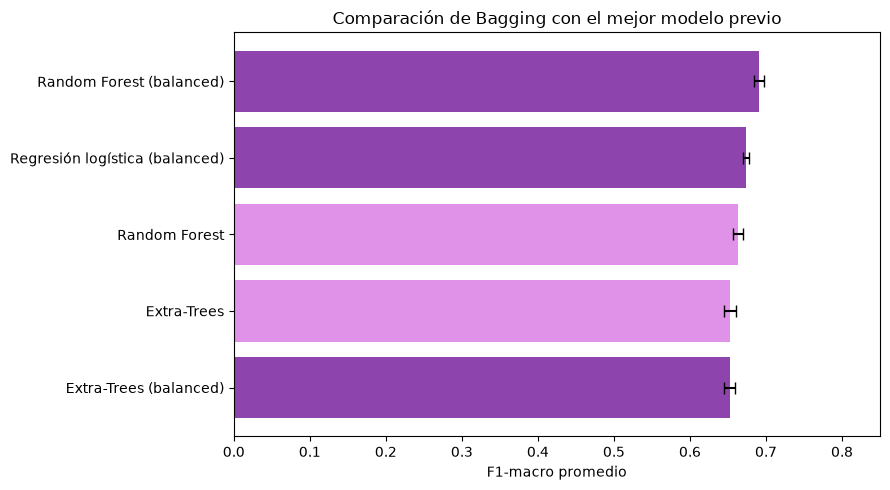

In [60]:
plt.figure(figsize=(9, 5))

colores = [
    "#8E44AD" if "balanced" in nombre else "#E091E8"
    for nombre in tabla_bagging_bank["Modelo"]
]

plt.barh(
    tabla_bagging_bank["Modelo"],
    tabla_bagging_bank["F1-macro"],
    xerr=tabla_bagging_bank["Desviación"],
    color=colores,
    capsize=4
)

plt.xlabel("F1-macro promedio")
plt.title("Comparación de Bagging con el mejor modelo previo")
plt.gca().invert_yaxis()
plt.xlim(0, 0.85)
plt.tight_layout()
plt.show()

La gráfica permite observar que Random Forest balanceado obtuvo el mejor F1-macro, seguido de la regresión logística balanceada. También se aprecia que la ponderación de clases mejoró considerablemente el desempeño de Random Forest, mientras que en Extra-Trees prácticamente no produjo cambios.

En general, los resultados indican que los métodos de Bagging pueden mejorar el desempeño respecto a los clasificadores individuales, aunque su efectividad depende del algoritmo y de la estrategia de balanceo utilizada.

Ahora pansando a *Boosting* a diferencia de Bagging, donde los árboles se construyen de manera independiente, los métodos de Boosting entrenan modelos secuencialmente para mejorar progresivamente las predicciones.

Se utilizarán los siguientes algoritmos:

- **AdaBoost** 
- **XGBoost** 
- **LightGBM** 

Debido al desbalance de clases, se compararán configuraciones con y sin ponderación de la clase minoritaria cuando el algoritmo lo permita.

In [61]:
conteo_no = (y_bank == 0).sum()
conteo_yes = (y_bank == 1).sum()

peso_positivo_bank = conteo_no / conteo_yes

print(f"Registros no: {conteo_no}")
print(f"Registros yes: {conteo_yes}")
print(f"Peso positivo: {peso_positivo_bank:.4f}")

Registros no: 36548
Registros yes: 4640
Peso positivo: 7.8767


In [62]:
class BoostingBalanceado(ClassifierMixin, BaseEstimator):

    def __init__(self, estimador=None, balancear=False):
        self.estimador = estimador
        self.balancear = balancear

    def fit(self, X, y):
        self.modelo_ = clone(self.estimador)

        if self.balancear:
            y_array = np.asarray(y)

            negativos = np.sum(y_array == 0)
            positivos = np.sum(y_array == 1)

            peso = negativos / positivos

            self.modelo_.set_params(
                scale_pos_weight=peso
            )

        self.modelo_.fit(X, y)

        self.classes_ = self.modelo_.classes_

        return self

    def predict(self, X):
        return self.modelo_.predict(X)

    def predict_proba(self, X):
        return self.modelo_.predict_proba(X)

In [63]:
modelos_boosting_bank = {

    "AdaBoost": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=1,
                random_state=RANDOM_STATE_BANK
            ),
            n_estimators=200,
            learning_rate=0.1,
            random_state=RANDOM_STATE_BANK
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=RANDOM_STATE_BANK,
            n_jobs=-1
        ))
    ]),

    "XGBoost (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", BoostingBalanceado(
            estimador=XGBClassifier(
                n_estimators=200,
                learning_rate=0.1,
                max_depth=6,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=RANDOM_STATE_BANK,
                n_jobs=-1
            ),
            balancear=True
        ))
    ]),

    "LightGBM": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", LGBMClassifier(
            n_estimators=200,
            learning_rate=0.1,
            objective="binary",
            verbosity=-1,
            random_state=RANDOM_STATE_BANK,
            n_jobs=-1
        ))
    ]),

    "LightGBM (balanced)": Pipeline([
        ("preprocesamiento", clone(preprocesamiento_arbol_bank)),
        ("modelo", BoostingBalanceado(
            estimador=LGBMClassifier(
                n_estimators=200,
                learning_rate=0.1,
                objective="binary",
                verbosity=-1,
                random_state=RANDOM_STATE_BANK,
                n_jobs=-1
            ),
            balancear=True
        ))
    ])
}

Se evaluarán AdaBoost, XGBoost y LightGBM mediante validación cruzada estratificada de cinco pliegues.

Para XGBoost y LightGBM se compararán versiones con y sin ponderación de clases, calculando los pesos únicamente con las observaciones de entrenamiento de cada pliegue.

In [64]:
resultados_boosting_bank = []

for nombre, modelo in modelos_boosting_bank.items():

    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(
        nombre,
        modelo
    )

    resultados_boosting_bank.append(resultado)

    print(
        f"F1-macro: "
        f"{resultado['F1-macro']:.4f} ± "
        f"{resultado['Desviación']:.4f}"
    )

    print(
        f"Sensibilidad yes: "
        f"{resultado['Sensibilidad yes']:.4f}"
    )

    print(
        f"Tiempo: "
        f"{resultado['Tiempo (s)']:.2f} s\n"
    )

Evaluando: AdaBoost
F1-macro: 0.6168 ± 0.0098
Sensibilidad yes: 0.1806
Tiempo: 6.31 s

Evaluando: XGBoost
F1-macro: 0.6636 ± 0.0106
Sensibilidad yes: 0.2759
Tiempo: 0.89 s

Evaluando: XGBoost (balanced)
F1-macro: 0.6869 ± 0.0049
Sensibilidad yes: 0.6052
Tiempo: 0.88 s

Evaluando: LightGBM
F1-macro: 0.6625 ± 0.0069
Sensibilidad yes: 0.2728
Tiempo: 0.40 s

Evaluando: LightGBM (balanced)
F1-macro: 0.6895 ± 0.0052
Sensibilidad yes: 0.6185
Tiempo: 0.45 s



In [65]:
referencias_boosting_bank = [
    resultado
    for resultado in (
        resultados_ponderados_bank
        + resultados_bagging_bank
    )
    if resultado["Modelo"] in [
        "Regresión logística (balanced)",
        "Random Forest (balanced)"
    ]
]

tabla_boosting_bank = pd.DataFrame(
    referencias_boosting_bank + resultados_boosting_bank
)

tabla_boosting_bank = (
    tabla_boosting_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_boosting_bank["F1-macro (media ± desv.)"] = (
    tabla_boosting_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_boosting_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_boosting_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Random Forest (balanced),0.6906 ± 0.0063,0.4709,0.8301
1,LightGBM (balanced),0.6895 ± 0.0052,0.6185,0.4478
2,XGBoost (balanced),0.6869 ± 0.0049,0.6052,0.8841
3,Regresión logística (balanced),0.6739 ± 0.0040,0.6287,0.2650
4,XGBoost,0.6636 ± 0.0106,0.2759,0.8920
5,LightGBM,0.6625 ± 0.0069,0.2728,0.4036
6,AdaBoost,0.6168 ± 0.0098,0.1806,6.3146


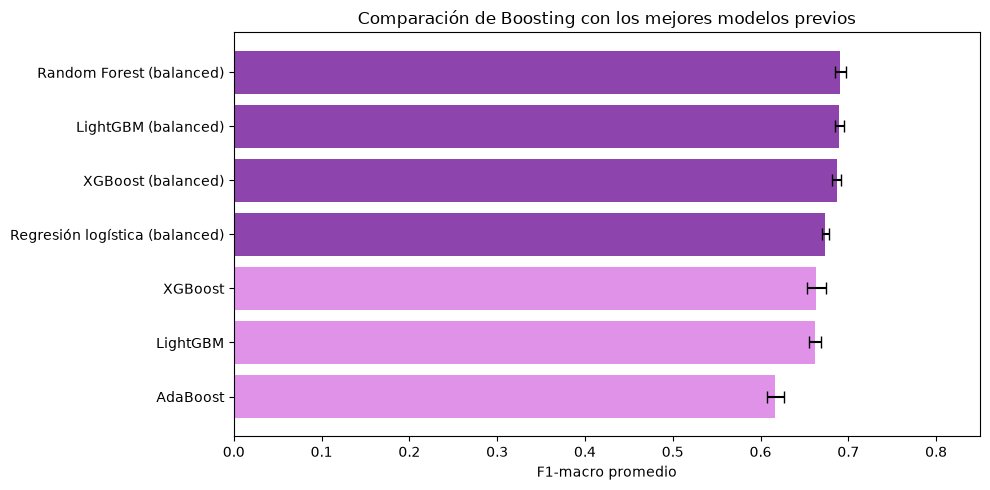

In [66]:
plt.figure(figsize=(10, 5))

colores = [
    "#8E44AD" if "balanced" in nombre else "#E091E8"
    for nombre in tabla_boosting_bank["Modelo"]
]

plt.barh(
    tabla_boosting_bank["Modelo"],
    tabla_boosting_bank["F1-macro"],
    xerr=tabla_boosting_bank["Desviación"],
    color=colores,
    capsize=4
)

plt.xlabel("F1-macro promedio")
plt.title("Comparación de Boosting con los mejores modelos previos")

plt.gca().invert_yaxis()
plt.xlim(0, 0.85)

plt.tight_layout()
plt.show()

Los resultados muestran que **LightGBM balanceado fue el mejor modelo de Boosting**, con un F1-macro de 0.6895 ± 0.0052 y una sensibilidad de 0.6185 para la clase `yes`. Aunque no superó a Random Forest balanceado (0.6906), la diferencia fue muy pequeña y logró identificar una proporción considerablemente mayor de clientes que contrataron el depósito.

XGBoost balanceado también presentó un buen desempeño, alcanzando un F1-macro de 0.6869 y una sensibilidad de 0.6052. En ambos algoritmos, la ponderación de clases produjo mejoras importantes respecto a sus versiones originales, especialmente en la identificación de la clase minoritaria.

Por otro lado, AdaBoost obtuvo el menor F1-macro (0.6168), además de presentar la sensibilidad más baja y el mayor tiempo de entrenamiento entre los modelos evaluados.

La gráfica muestra que Random Forest, LightGBM y XGBoost balanceados obtuvieron resultados bastante similares en F1-macro, con poca variación entre los cinco pliegues. Sin embargo, LightGBM presentó una mejor combinación de F1-macro, sensibilidad y eficiencia computacional.

En general, **los resultados confirman la importancia de considerar varias métricas al seleccionar un clasificador**, ya que el modelo con mayor F1-macro no necesariamente es el más adecuado cuando también interesa identificar correctamente a los clientes de la clase minoritaria.

Ahora, vamos a evaluar dos estrategias para combinar diferentes clasificadores: Voting y Stacking.Se utilizarán regresión logística, Random Forest y LightGBM, todos con ponderación de clases, debido a sus resultados anteriores. Estos modelos presentan diferentes mecanismos de aprendizaje y comportamientos respecto a la clase minoritaria, lo que podría favorecer su combinación. Todos los ensambles se evaluarán utilizando los mismos cinco pliegues estratificados y las métricas establecidas anteriormente.

In [67]:
# Recuperar los mejores modelos anteriores
modelo_lr_bank = clone(
    modelos_ponderados_bank["Regresión logística (balanced)"]
)

modelo_rf_bank = clone(
    modelos_bagging_bank["Random Forest (balanced)"]
)

modelo_lgbm_bank = clone(
    modelos_boosting_bank["LightGBM (balanced)"]
)

# Clasificadores que formarán los ensambles
estimadores_voting_bank = [
    ("lr", modelo_lr_bank),
    ("rf", modelo_rf_bank),
    ("lgbm", modelo_lgbm_bank)
]

Se evaluarán Voting duro y Voting suave utilizando los tres clasificadores seleccionados.

In [68]:
modelos_voting_bank = {
    "Voting duro": VotingClassifier(
        estimators=estimadores_voting_bank,
        voting="hard",
        n_jobs=1
    ),

    "Voting suave": VotingClassifier(
        estimators=estimadores_voting_bank,
        voting="soft",
        n_jobs=1
    )
}

resultados_voting_bank = []

for nombre, modelo in modelos_voting_bank.items():

    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(
        nombre,
        modelo
    )

    resultados_voting_bank.append(resultado)

    print(
        f"F1-macro: "
        f"{resultado['F1-macro']:.4f} ± "
        f"{resultado['Desviación']:.4f}"
    )
    print(
        f"Sensibilidad yes: "
        f"{resultado['Sensibilidad yes']:.4f}"
    )
    print(
        f"Tiempo: "
        f"{resultado['Tiempo (s)']:.2f} s\n"
    )

Evaluando: Voting duro
F1-macro: 0.7035 ± 0.0035
Sensibilidad yes: 0.5942
Tiempo: 1.62 s

Evaluando: Voting suave
F1-macro: 0.7060 ± 0.0050
Sensibilidad yes: 0.5948
Tiempo: 1.46 s



Para Stacking se utilizarán los mismos tres clasificadores base, combinando sus predicciones mediante una regresión logística. El metaclasificador se entrenará a partir de predicciones generadas mediante validación cruzada interna de tres pliegues. Esto permite evitar que aprenda directamente de predicciones realizadas sobre los mismos registros utilizados para entrenar cada modelo base.


In [69]:
cv_interno_stacking_bank = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE_BANK
)

modelo_stacking_bank = StackingClassifier(
    estimators=[
        ("lr", clone(modelo_lr_bank)),
        ("rf", clone(modelo_rf_bank)),
        ("lgbm", clone(modelo_lgbm_bank))
    ],
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE_BANK
    ),
    cv=cv_interno_stacking_bank,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=1
)

print("Evaluando: Stacking")

resultado_stacking_bank = evaluar_modelo_bank(
    "Stacking",
    modelo_stacking_bank
)

resultados_stacking_bank = [
    resultado_stacking_bank
]

print(
    f"F1-macro: "
    f"{resultado_stacking_bank['F1-macro']:.4f} ± "
    f"{resultado_stacking_bank['Desviación']:.4f}"
)

print(
    f"Sensibilidad yes: "
    f"{resultado_stacking_bank['Sensibilidad yes']:.4f}"
)

print(
    f"Tiempo: "
    f"{resultado_stacking_bank['Tiempo (s)']:.2f} s"
)

Evaluando: Stacking
F1-macro: 0.6685 ± 0.0075
Sensibilidad yes: 0.2828
Tiempo: 6.03 s


Pasemos a comprar resultados:

In [70]:
referencias_ensambles_bank = [
    resultado
    for resultado in (
        resultados_ponderados_bank
        + resultados_bagging_bank
        + resultados_boosting_bank
    )
    if resultado["Modelo"] in [
        "Regresión logística (balanced)",
        "Random Forest (balanced)",
        "LightGBM (balanced)"
    ]
]

tabla_ensambles_bank = pd.DataFrame(
    referencias_ensambles_bank
    + resultados_voting_bank
    + resultados_stacking_bank
)

tabla_ensambles_bank = (
    tabla_ensambles_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_ensambles_bank["F1-macro (media ± desv.)"] = (
    tabla_ensambles_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_ensambles_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_ensambles_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Voting suave,0.7060 ± 0.0050,0.5948,1.4574
1,Voting duro,0.7035 ± 0.0035,0.5942,1.6226
2,Random Forest (balanced),0.6906 ± 0.0063,0.4709,0.8301
3,LightGBM (balanced),0.6895 ± 0.0052,0.6185,0.4478
4,Regresión logística (balanced),0.6739 ± 0.0040,0.6287,0.2650
5,Stacking,0.6685 ± 0.0075,0.2828,6.0269


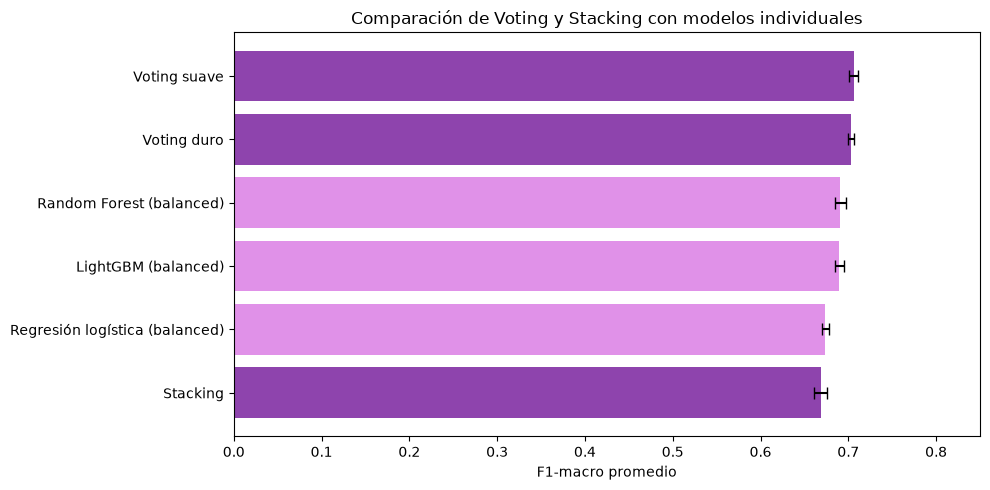

In [71]:
plt.figure(figsize=(10, 5))

colores = [
    "#8E44AD"
    if nombre in ["Voting duro", "Voting suave", "Stacking"]
    else "#E091E8"
    for nombre in tabla_ensambles_bank["Modelo"]
]

plt.barh(
    tabla_ensambles_bank["Modelo"],
    tabla_ensambles_bank["F1-macro"],
    xerr=tabla_ensambles_bank["Desviación"],
    color=colores,
    capsize=4
)

plt.xlabel("F1-macro promedio")
plt.title("Comparación de Voting y Stacking con modelos individuales")

plt.gca().invert_yaxis()
plt.xlim(0, 0.85)

plt.tight_layout()
plt.show()

Los resultados muestran que **Voting suave obtuvo el mejor F1-macro de todos los modelos evaluados hasta ahora (0.7060 ± 0.0050)**, seguido de Voting duro (0.7035 ± 0.0035). Ambos superaron a Random Forest balanceado, que anteriormente había presentado el mejor desempeño con un F1-macro de 0.6906.

Además, Voting suave alcanzó una sensibilidad de 0.5948 para la clase `yes`, superior a la de Random Forest balanceado (0.4709), aunque ligeramente inferior a la de LightGBM y regresión logística balanceados.

La gráfica muestra que Voting duro y suave presentaron resultados similares, con poca variación entre los cinco pliegues. En cambio, Stacking tuvo un desempeño inferior y requirió un mayor tiempo de entrenamiento.

En general, los resultados sugieren que **combinar clasificadores con diferentes mecanismos de aprendizaje puede mejorar el desempeño**, pero que utilizar un método más complejo, como Stacking, no garantiza obtener mejores resultados.

Antes de descartar Stacking, podemos realizar un paso adicional: utilizar un metaclasificador balanceado.

In [72]:
modelo_stacking_balanceado_bank = StackingClassifier(
    estimators=[
        ("lr", clone(modelo_lr_bank)),
        ("rf", clone(modelo_rf_bank)),
        ("lgbm", clone(modelo_lgbm_bank))
    ],
    final_estimator=LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE_BANK
    ),
    cv=cv_interno_stacking_bank,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=1
)

resultado_stacking_balanceado_bank = evaluar_modelo_bank(
    "Stacking (balanced)",
    modelo_stacking_balanceado_bank
)

display(pd.DataFrame([resultado_stacking_balanceado_bank]).round(4))

,Modelo,F1-macro,Desviación,Sensibilidad yes,Tiempo (s)
0,Stacking (balanced),0.6737,0.0061,0.647,6.8582


Debido a la baja sensibilidad obtenida por Stacking, se realizó un experimento adicional utilizando `class_weight="balanced"` en el metaclasificador. Los resultados muestran que **la sensibilidad de la clase `yes` aumentó considerablemente, pasando de 0.2828 a 0.6470**. Esto sugiere que el metaclasificador original favorecía la clase mayoritaria y que la ponderación permitió identificar una proporción mucho mayor de clientes que contrataron el depósito.

Sin embargo, el F1-macro solamente mejoró de 0.6685 a 0.6737, por lo que el aumento de sensibilidad no se tradujo en una mejora importante del desempeño general. Una posible explicación es que también aumentó la cantidad de falsos positivos.

En conclusión, el balanceo permitió mejorar considerablemente la identificación de la clase minoritaria, pero **Voting suave continúa siendo el mejor modelo según F1-macro (0.7060)**. Esto confirma que mejorar una métrica no necesariamente implica mejorar todas las demás.

#### Optimización de hiperparámetros
Después de evaluar los clasificadores individuales y los métodos de ensamble, se realizará una búsqueda de hiperparámetros para mejorar el desempeño de los modelos más prometedores.

Se seleccionaron Random Forest, XGBoost y LightGBM debido a sus resultados anteriores y a que permiten controlar diferentes aspectos del aprendizaje, como la profundidad de los árboles, la cantidad de estimadores y la regularización.

Para cada modelo se utilizará RandomizedSearchCV, evaluando 50 configuraciones mediante validación cruzada estratificada de cinco pliegues. La métrica de optimización será F1-macro. Los modelos optimizados se compararán posteriormente con Voting suave, que obtuvo el mejor F1-macro hasta este punto (0.7060).

In [73]:
# Recuperar Random Forest balanceado
pipeline_rf_bank = clone(
    modelos_bagging_bank["Random Forest (balanced)"]
)

# Espacio de búsqueda
parametros_rf_bank = {
    "modelo__n_estimators": randint(100, 501),
    "modelo__max_depth": [None, 5, 10, 15, 20, 30, 50],
    "modelo__min_samples_split": randint(2, 21),
    "modelo__min_samples_leaf": randint(1, 11),
    "modelo__max_features": ["sqrt", "log2", 0.5, 0.8],
    "modelo__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

busqueda_rf_bank = RandomizedSearchCV(
    estimator=pipeline_rf_bank,
    param_distributions=parametros_rf_bank,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_bank,
    random_state=RANDOM_STATE_BANK,
    n_jobs=1,
    verbose=1,
    refit=True
)

In [74]:
busqueda_rf_bank.fit(X_bank, y_bank)

print("Mejor F1-macro:")
print(round(busqueda_rf_bank.best_score_, 4))

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_rf_bank.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro:
0.7157

Mejores hiperparámetros:
modelo__class_weight: balanced_subsample
modelo__max_depth: 20
modelo__max_features: log2
modelo__min_samples_leaf: 1
modelo__min_samples_split: 8
modelo__n_estimators: 125


In [75]:
modelo_rf_optimizado_bank = clone(
    busqueda_rf_bank.best_estimator_
)

resultado_rf_optimizado_bank = evaluar_modelo_bank(
    "Random Forest optimizado",
    modelo_rf_optimizado_bank
)

resultados_optimizados_bank = [
    resultado_rf_optimizado_bank
]

display(
    pd.DataFrame(
        resultados_optimizados_bank
    ).round(4)
)

,Modelo,F1-macro,Desviación,Sensibilidad yes,Tiempo (s)
0,Random Forest optimizado,0.7157,0.0061,0.5386,0.5664


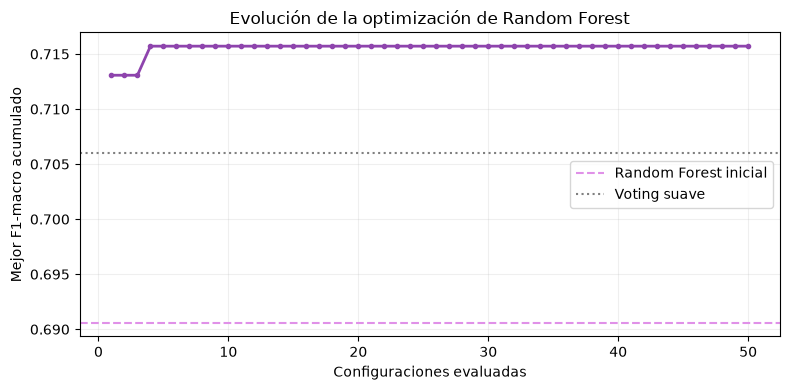

In [76]:
resultados_busqueda_rf = pd.DataFrame(
    busqueda_rf_bank.cv_results_
)

f1_configuraciones_rf = (
    resultados_busqueda_rf["mean_test_score"].to_numpy()
)

mejor_f1_acumulado_rf = np.maximum.accumulate(
    f1_configuraciones_rf
)

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(mejor_f1_acumulado_rf) + 1),
    mejor_f1_acumulado_rf,
    color="#8E44AD",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.axhline(
    y=0.6906,
    color="#E091E8",
    linestyle="--",
    label="Random Forest inicial"
)

plt.axhline(
    y=0.7060,
    color="gray",
    linestyle=":",
    label="Voting suave"
)

plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1-macro acumulado")
plt.title("Evolución de la optimización de Random Forest")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

La optimización de Random Forest permitió mejorar considerablemente su desempeño, alcanzando un **F1-macro de 0.7157 ± 0.0061**, superior al resultado inicial de 0.6906 y al obtenido por Voting suave (0.7060).

La sensibilidad de la clase `yes` también aumentó de 0.4709 a 0.5386, lo que indica que la configuración optimizada permitió identificar una mayor proporción de clientes que contrataron el depósito.

La mejor combinación utilizó 125 árboles, profundidad máxima de 20, `max_features="log2"`, un mínimo de ocho observaciones para dividir un nodo y ponderación `balanced_subsample`. Estos resultados muestran que controlar la complejidad de los árboles puede ser más beneficioso que simplemente aumentar su cantidad.

En la gráfica se observa que **el mejor F1-macro se encontró aproximadamente en la cuarta configuración**, después de lo cual no se registraron mejoras adicionales. Esto sugiere que la búsqueda alcanzó rápidamente una meseta dentro del espacio de hiperparámetros explorado.

En general, Random Forest optimizado se posiciona como el mejor modelo hasta este punto, aunque Voting suave continúa presentando una sensibilidad superior para la clase minoritaria.

Cabe señalar que estos resultados son exploratorios, ya que la evaluación posterior reutilizó los mismos pliegues empleados durante la optimización, por lo tanto, el desempeño podría ser optimista y sería necesario utilizar validación cruzada anidada o un conjunto de prueba independiente para obtener una estimación menos sesgada.

Ahora, se hará la optimización de XGBoost

XGBoost con ponderación de clases obtuvo un F1-macro de 0.6869 y una sensibilidad de 0.6052 para la clase `yes`, superando considerablemente a su versión sin balanceo.

En esta sección se realizará una búsqueda aleatoria de 50 configuraciones de hiperparámetros para intentar mejorar su desempeño. Se explorarán diferentes cantidades de árboles, profundidades, tasas de aprendizaje y parámetros de regularización. También se conservará la ponderación de clases, calculada exclusivamente con los datos de entrenamiento de cada pliegue.

In [77]:
# Recuperar el pipeline balanceado
pipeline_xgb_bank = clone(
    modelos_boosting_bank["XGBoost (balanced)"]
)

# Espacio de búsqueda
parametros_xgb_bank = {
    "modelo__estimador__n_estimators": randint(100, 501),
    "modelo__estimador__max_depth": randint(2, 11),
    "modelo__estimador__learning_rate": loguniform(0.01, 0.3),
    "modelo__estimador__subsample": uniform(0.6, 0.4),
    "modelo__estimador__colsample_bytree": uniform(0.5, 0.5),
    "modelo__estimador__min_child_weight": randint(1, 11),
    "modelo__estimador__reg_lambda": loguniform(0.1, 20),
    "modelo__estimador__gamma": uniform(0, 5)
}

busqueda_xgb_bank = RandomizedSearchCV(
    estimator=pipeline_xgb_bank,
    param_distributions=parametros_xgb_bank,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_bank,
    random_state=RANDOM_STATE_BANK,
    n_jobs=1,
    verbose=1,
    refit=True
)

In [78]:
busqueda_xgb_bank.fit(X_bank, y_bank)

print("Mejor F1-macro:")
print(round(busqueda_xgb_bank.best_score_, 4))

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_xgb_bank.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro:
0.6994

Mejores hiperparámetros:
modelo__estimador__colsample_bytree: 0.6070360088165785
modelo__estimador__gamma: 4.644901163397354
modelo__estimador__learning_rate: 0.01793085931148831
modelo__estimador__max_depth: 10
modelo__estimador__min_child_weight: 3
modelo__estimador__n_estimators: 410
modelo__estimador__reg_lambda: 0.192377565279175
modelo__estimador__subsample: 0.6702731097467798


In [79]:
modelo_xgb_optimizado_bank = clone(
    busqueda_xgb_bank.best_estimator_
)

resultado_xgb_optimizado_bank = evaluar_modelo_bank(
    "XGBoost optimizado",
    modelo_xgb_optimizado_bank
)

resultados_optimizados_bank.append(
    resultado_xgb_optimizado_bank
)

display(
    pd.DataFrame(
        [resultado_xgb_optimizado_bank]
    ).round(4)
)

,Modelo,F1-macro,Desviación,Sensibilidad yes,Tiempo (s)
0,XGBoost optimizado,0.6994,0.0041,0.6106,2.4953


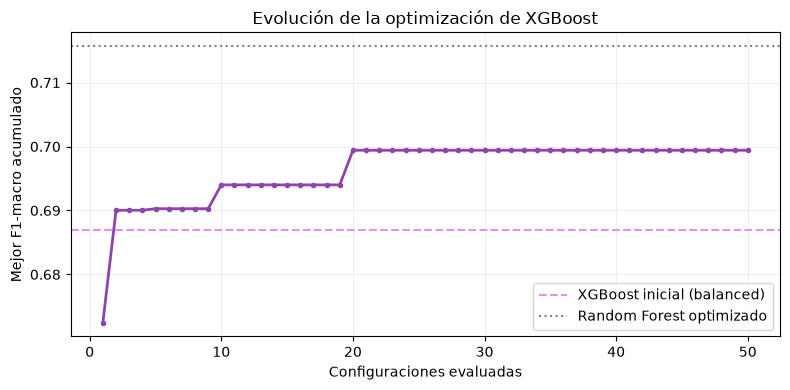

In [80]:
resultados_busqueda_xgb = pd.DataFrame(
    busqueda_xgb_bank.cv_results_
)

f1_configuraciones_xgb = (
    resultados_busqueda_xgb["mean_test_score"].to_numpy()
)

mejor_f1_acumulado_xgb = np.maximum.accumulate(
    f1_configuraciones_xgb
)

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(mejor_f1_acumulado_xgb) + 1),
    mejor_f1_acumulado_xgb,
    color="#8E44AD",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.axhline(
    y=0.6869,
    color="#E091E8",
    linestyle="--",
    label="XGBoost inicial (balanced)"
)

plt.axhline(
    y=0.7157,
    color="gray",
    linestyle=":",
    label="Random Forest optimizado"
)

plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1-macro acumulado")
plt.title("Evolución de la optimización de XGBoost")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

La optimización de XGBoost permitió mejorar su F1-macro de 0.6869 a **0.6994 ± 0.0041**, mientras que la sensibilidad de la clase `yes` aumentó ligeramente de 0.6052 a 0.6106.

Aunque los resultados mejoraron respecto a la configuración inicial, XGBoost optimizado no logró superar a Random Forest optimizado, que obtuvo un F1-macro de 0.7157. Sin embargo, XGBoost continúa presentando una mayor sensibilidad para la clase minoritaria.

En la gráfica se observa que el desempeño mejoró durante las primeras configuraciones, alcanzando el mejor F1-macro aproximadamente en la configuración 20. A partir de ese momento, la curva permaneció constante, lo que sugiere que la búsqueda alcanzó una meseta dentro del espacio de hiperparámetros explorado.

Por otro lado, el tiempo promedio de entrenamiento aumentó de 0.4299 a 1.1084 segundos, lo que indica que la mejora en el desempeño también implicó un mayor costo computacional.

En general, la optimización produjo mejoras moderadas, pero **Random Forest continúa siendo el mejor modelo según F1-macro**, mientras que XGBoost mantiene una ventaja en sensibilidad.

Ahora pasando con la optimización de LightGBM. En los puntos anteriores, LightGBM balanceado obtuvo un F1-macro de 0.6895 y una sensibilidad de 0.6185 para la clase yes, destacando también por su bajo tiempo de entrenamiento.

En esta sección se realizará una búsqueda aleatoria de 50 configuraciones de hiperparámetros para intentar mejorar su desempeño.

Se explorarán diferentes cantidades de árboles, tasas de aprendizaje, número de hojas, profundidad máxima y parámetros de regularización. Se mantendrá la ponderación de clases, calculada únicamente con los datos de entrenamiento de cada pliegue.

In [81]:
# Recuperar LightGBM balanceado
pipeline_lgbm_bank = clone(
    modelos_boosting_bank["LightGBM (balanced)"]
)

# Espacio de búsqueda
parametros_lgbm_bank = {
    "modelo__estimador__n_estimators": randint(100, 501),
    "modelo__estimador__learning_rate": loguniform(0.01, 0.3),
    "modelo__estimador__num_leaves": randint(15, 128),
    "modelo__estimador__max_depth": [-1, 5, 10, 15, 20, 30],
    "modelo__estimador__min_child_samples": randint(10, 101),
    "modelo__estimador__subsample": uniform(0.6, 0.4),
    "modelo__estimador__subsample_freq": [1],
    "modelo__estimador__colsample_bytree": uniform(0.5, 0.5),
    "modelo__estimador__reg_lambda": loguniform(0.01, 20),
    "modelo__estimador__reg_alpha": loguniform(0.001, 10)
}

busqueda_lgbm_bank = RandomizedSearchCV(
    estimator=pipeline_lgbm_bank,
    param_distributions=parametros_lgbm_bank,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_bank,
    random_state=RANDOM_STATE_BANK,
    n_jobs=1,
    verbose=1,
    refit=True
)

In [82]:
busqueda_lgbm_bank.fit(X_bank, y_bank)

print("Mejor F1-macro:")
print(round(busqueda_lgbm_bank.best_score_, 4))

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_lgbm_bank.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejor F1-macro:
0.7095

Mejores hiperparámetros:
modelo__estimador__colsample_bytree: 0.7464356883094481
modelo__estimador__learning_rate: 0.014398277155583663
modelo__estimador__max_depth: 10
modelo__estimador__min_child_samples: 91
modelo__estimador__n_estimators: 110
modelo__estimador__num_leaves: 103
modelo__estimador__reg_alpha: 1.4834718606862172
modelo__estimador__reg_lambda: 10.575204408091704
modelo__estimador__subsample: 0.886972327351927
modelo__estimador__subsample_freq: 1


In [83]:
modelo_lgbm_optimizado_bank = clone(
    busqueda_lgbm_bank.best_estimator_
)

resultado_lgbm_optimizado_bank = evaluar_modelo_bank(
    "LightGBM optimizado",
    modelo_lgbm_optimizado_bank
)

resultados_optimizados_bank.append(
    resultado_lgbm_optimizado_bank
)

display(
    pd.DataFrame(
        [resultado_lgbm_optimizado_bank]
    ).round(4)
)

,Modelo,F1-macro,Desviación,Sensibilidad yes,Tiempo (s)
0,LightGBM optimizado,0.7095,0.0034,0.5987,0.4829


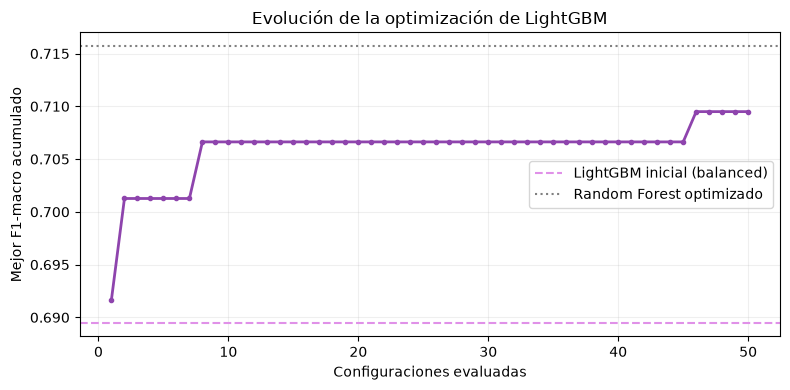

In [84]:
resultados_busqueda_lgbm = pd.DataFrame(
    busqueda_lgbm_bank.cv_results_
)

f1_configuraciones_lgbm = (
    resultados_busqueda_lgbm["mean_test_score"].to_numpy()
)

mejor_f1_acumulado_lgbm = np.maximum.accumulate(
    f1_configuraciones_lgbm
)

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(mejor_f1_acumulado_lgbm) + 1),
    mejor_f1_acumulado_lgbm,
    color="#8E44AD",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.axhline(
    y=0.6895,
    color="#E091E8",
    linestyle="--",
    label="LightGBM inicial (balanced)"
)

plt.axhline(
    y=0.7157,
    color="gray",
    linestyle=":",
    label="Random Forest optimizado"
)

plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1-macro acumulado")
plt.title("Evolución de la optimización de LightGBM")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

La optimización de LightGBM permitió mejorar su F1-macro de 0.6895 a **0.7095 ± 0.0034**, superando también el resultado de XGBoost optimizado (0.6994). Sin embargo, no logró superar a Random Forest optimizado, que continúa siendo el mejor modelo con un F1-macro de 0.7157.

Por otro lado, la sensibilidad de la clase `yes` disminuyó ligeramente de 0.6185 a 0.5987, lo que muestra que mejorar el F1-macro no necesariamente implica identificar más observaciones de la clase minoritaria.

La mejor configuración utilizó 110 árboles, una tasa de aprendizaje aproximada de 0.0144, profundidad máxima de 10 y un mínimo de 91 observaciones por hoja. En la gráfica se observa que el F1-macro mejoró rápidamente durante las primeras configuraciones y posteriormente permaneció estable durante gran parte de la búsqueda. Sin embargo, cerca de la configuración 46 se encontró una nueva mejora, alcanzando el mejor resultado de 0.7095.

En general,*LightGBM optimizado presentó una buena combinación de desempeño y eficiencia computacional, aunque Random Forest continúa obteniendo el mayor F1-macro.

In [85]:
referencia_voting_bank = [
    resultado
    for resultado in resultados_voting_bank
    if resultado["Modelo"] == "Voting suave"
]

tabla_optimizados_bank = pd.DataFrame(
    resultados_optimizados_bank
    + referencia_voting_bank
)

tabla_optimizados_bank = (
    tabla_optimizados_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_optimizados_bank["F1-macro (media ± desv.)"] = (
    tabla_optimizados_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_optimizados_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_optimizados_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Random Forest optimizado,0.7157 ± 0.0061,0.5386,0.5664
1,LightGBM optimizado,0.7095 ± 0.0034,0.5987,0.4829
2,Voting suave,0.7060 ± 0.0050,0.5948,1.4574
3,XGBoost optimizado,0.6994 ± 0.0041,0.6106,2.4953


Por el moento, asi se van viendo los resultados. 

Ahora, pasemos a la optimizacion de voting, para ver si supera el F1 del Rabdon Forest optimizado. 

In [86]:
estimadores_optimizados_bank = [
    ("rf", clone(modelo_rf_optimizado_bank)),
    ("xgb", clone(modelo_xgb_optimizado_bank)),
    ("lgbm", clone(modelo_lgbm_optimizado_bank))
]

modelos_voting_opt_bank = {
    "Voting duro optimizado": VotingClassifier(
        estimators=estimadores_optimizados_bank,
        voting="hard",
        n_jobs=1
    ),

    "Voting suave optimizado": VotingClassifier(
        estimators=estimadores_optimizados_bank,
        voting="soft",
        n_jobs=1
    )
}

In [87]:
resultados_voting_opt_bank = []

for nombre, modelo in modelos_voting_opt_bank.items():

    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(nombre, modelo)

    resultados_voting_opt_bank.append(resultado)

    print(
        f"F1-macro: {resultado['F1-macro']:.4f} "
        f"± {resultado['Desviación']:.4f}"
    )

    print(
        f"Sensibilidad yes: "
        f"{resultado['Sensibilidad yes']:.4f}"
    )

    print(
        f"Tiempo: {resultado['Tiempo (s)']:.2f} s\n"
    )

Evaluando: Voting duro optimizado
F1-macro: 0.7124 ± 0.0040
Sensibilidad yes: 0.5847
Tiempo: 3.04 s

Evaluando: Voting suave optimizado
F1-macro: 0.7132 ± 0.0051
Sensibilidad yes: 0.5871
Tiempo: 3.28 s



In [88]:
estimadores_optimizados_bank = [
    ("rf", clone(modelo_rf_optimizado_bank)),
    ("xgb", clone(modelo_xgb_optimizado_bank)),
    ("lgbm", clone(modelo_lgbm_optimizado_bank))
]

modelos_voting_opt_bank = {
    "Voting duro optimizado": VotingClassifier(
        estimators=estimadores_optimizados_bank,
        voting="hard",
        n_jobs=1
    ),

    "Voting suave optimizado": VotingClassifier(
        estimators=estimadores_optimizados_bank,
        voting="soft",
        n_jobs=1
    )
}

In [89]:
resultados_voting_opt_bank = []

for nombre, modelo in modelos_voting_opt_bank.items():

    print(f"Evaluando: {nombre}")

    resultado = evaluar_modelo_bank(nombre, modelo)

    resultados_voting_opt_bank.append(resultado)

    print(
        f"F1-macro: {resultado['F1-macro']:.4f} "
        f"± {resultado['Desviación']:.4f}"
    )

    print(
        f"Sensibilidad yes: "
        f"{resultado['Sensibilidad yes']:.4f}"
    )

    print(
        f"Tiempo: {resultado['Tiempo (s)']:.2f} s\n"
    )

Evaluando: Voting duro optimizado
F1-macro: 0.7124 ± 0.0040
Sensibilidad yes: 0.5847
Tiempo: 3.42 s

Evaluando: Voting suave optimizado
F1-macro: 0.7132 ± 0.0051
Sensibilidad yes: 0.5871
Tiempo: 3.46 s



In [90]:
tabla_voting_opt_bank = pd.DataFrame(
    resultados_optimizados_bank
    + resultados_voting_opt_bank
    + [
        resultado
        for resultado in resultados_voting_bank
        if resultado["Modelo"] == "Voting suave"
    ]
)

tabla_voting_opt_bank = (
    tabla_voting_opt_bank
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

tabla_voting_opt_bank["F1-macro (media ± desv.)"] = (
    tabla_voting_opt_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_voting_opt_bank["Desviación"].map("{:.4f}".format)
)

display(
    tabla_voting_opt_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Random Forest optimizado,0.7157 ± 0.0061,0.5386,0.5664
1,Voting suave optimizado,0.7132 ± 0.0051,0.5871,3.4616
2,Voting duro optimizado,0.7124 ± 0.0040,0.5847,3.4161
3,LightGBM optimizado,0.7095 ± 0.0034,0.5987,0.4829
4,Voting suave,0.7060 ± 0.0050,0.5948,1.4574
5,XGBoost optimizado,0.6994 ± 0.0041,0.6106,2.4953


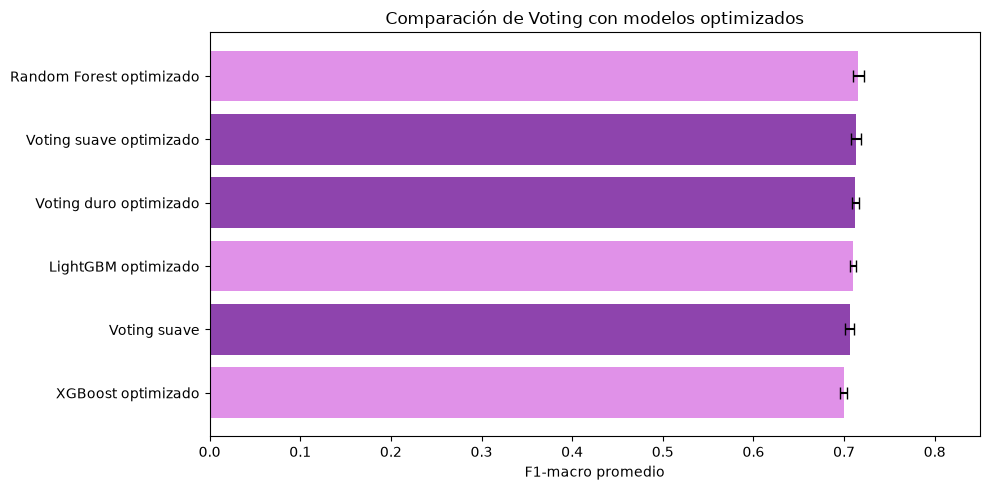

In [91]:
plt.figure(figsize=(10, 5))

colores = [
    "#8E44AD" if "Voting" in nombre else "#E091E8"
    for nombre in tabla_voting_opt_bank["Modelo"]
]

plt.barh(
    tabla_voting_opt_bank["Modelo"],
    tabla_voting_opt_bank["F1-macro"],
    xerr=tabla_voting_opt_bank["Desviación"],
    color=colores,
    capsize=4
)

plt.xlabel("F1-macro promedio")
plt.title("Comparación de Voting con modelos optimizados")

plt.gca().invert_yaxis()
plt.xlim(0, 0.85)

plt.tight_layout()
plt.show()

Los resultados muestran que **Voting suave optimizado alcanzó un F1-macro de 0.7132 ± 0.0051**, mejorando el resultado del Voting suave original (0.7060). Voting duro optimizado presentó un desempeño muy similar, con un F1-macro de 0.7124 ± 0.0040.

Sin embargo, ninguno de los dos logró superar a Random Forest optimizado, aunque la diferencia fue pequeña por lo que no es posible afirmar que Random Forest sea estadísticamente superior únicamente con estos resultados.

Por otro lado, Voting suave optimizado obtuvo una sensibilidad de 0.5871 para la clase `yes`, superior a la de Random Forest optimizado (0.5386), aunque ligeramente inferior a la del Voting suave original (0.5948).

La gráfica muestra que los modelos optimizados presentan resultados bastante cercanos, con poca variación entre los cinco pliegues. Esto sugiere que la combinación de clasificadores puede ofrecer mejoras respecto a sus versiones iniciales, pero no necesariamente superar al mejor modelo individual.

Además, Voting requirió un mayor tiempo de entrenamiento, debido a que necesita ajustar tres clasificadores.

En general, **Random Forest optimizado se mantiene como el mejor modelo según F1-macro**, mientras que Voting suave optimizado representa una alternativa competitiva con mayor sensibilidad para la clase minoritaria.

Algo que cabe señalar es que los resultados de los modelos optimizados y sus combinaciones deben interpretarse como comparaciones exploratorias, debido a que los hiperparámetros fueron seleccionados utilizando las mismas particiones empleadas posteriormente para evaluar el desempeño.

Aunque el preprocesamiento y el entrenamiento se realizan dentro de cada pliegue, la selección previa de hiperparámetros puede introducir cierto optimismo en las métricas.

Para obtener una estimación más independiente del desempeño final sería necesario utilizar validación cruzada anidada o un conjunto de prueba reservado que no haya participado en la selección de modelos.

#### Tabla comparativa general

Después de evaluar los clasificadores individuales, las estrategias de balanceo, los métodos de ensamble y la optimización de hiperparámetros, se realizará una comparación general de todos los modelos.

In [92]:
# Reunir los resultados de todos los experimentos
resultados_generales_bank = (
    resultados_individuales_bank
    + resultados_ponderados_bank
    + resultados_smotenc_bank
    + resultados_bagging_bank
    + resultados_boosting_bank
    + resultados_voting_bank
    + resultados_stacking_bank
    + [resultado_stacking_balanceado_bank]
    + resultados_optimizados_bank
    + resultados_voting_opt_bank
)

# Construir tabla general
tabla_general_bank = pd.DataFrame(
    resultados_generales_bank
)

# Evitar duplicados y ordenar por F1-macro
tabla_general_bank = (
    tabla_general_bank
    .drop_duplicates(subset="Modelo", keep="last")
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

# Formatear F1-macro
tabla_general_bank["F1-macro (media ± desv.)"] = (
    tabla_general_bank["F1-macro"].map("{:.4f}".format)
    + " ± "
    + tabla_general_bank["Desviación"].map("{:.4f}".format)
)

# Mostrar tabla final
display(
    tabla_general_bank[
        [
            "Modelo",
            "F1-macro (media ± desv.)",
            "Sensibilidad yes",
            "Tiempo (s)"
        ]
    ].round(4)
)

,Modelo,F1-macro (media ± desv.),Sensibilidad yes,Tiempo (s)
0,Random Forest optimizado,0.7157 ± 0.0061,0.5386,0.5664
1,Voting suave optimizado,0.7132 ± 0.0051,0.5871,3.4616
2,Voting duro optimizado,0.7124 ± 0.0040,0.5847,3.4161
3,LightGBM optimizado,0.7095 ± 0.0034,0.5987,0.4829
4,Voting suave,0.7060 ± 0.0050,0.5948,1.4574
5,Voting duro,0.7035 ± 0.0035,0.5942,1.6226
6,XGBoost optimizado,0.6994 ± 0.0041,0.6106,2.4953
7,Random Forest (balanced),0.6906 ± 0.0063,0.4709,0.8301
8,LightGBM (balanced),0.6895 ± 0.0052,0.6185,0.4478
9,XGBoost (balanced),0.6869 ± 0.0049,0.6052,0.8841


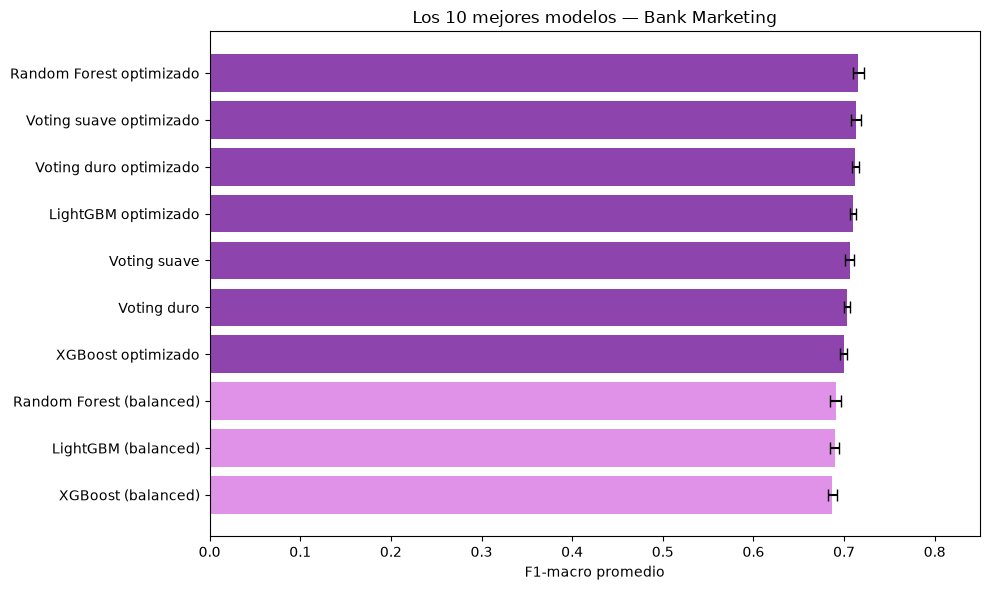

In [93]:
top_10_bank = tabla_general_bank.head(10).copy()

colores = [
    "#8E44AD"
    if (
        "optimizado" in nombre.lower()
        or "voting" in nombre.lower()
    )
    else "#E091E8"
    for nombre in top_10_bank["Modelo"]
]

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_bank["Modelo"],
    top_10_bank["F1-macro"],
    xerr=top_10_bank["Desviación"],
    color=colores,
    capsize=4
)

plt.xlabel("F1-macro promedio")
plt.title("Los 10 mejores modelos — Bank Marketing")

plt.gca().invert_yaxis()
plt.xlim(0, 0.85)

plt.tight_layout()
plt.show()

La gráfica muestra que Random Forest optimizado obtuvo el mayor F1-macro (0.7157), seguido de Voting suave optimizado (0.7132) y Voting duro optimizado (0.7124). Sin embargo, las diferencias entre estos modelos fueron pequeñas.

También se observa que la optimización de hiperparámetros mejoró el desempeño de Random Forest, LightGBM y XGBoost respecto a sus versiones iniciales. Por otro lado, los métodos de Voting se mantuvieron entre los mejores resultados, lo que demuestra que combinar diferentes clasificadores puede ser una estrategia competitiva.

En general, los métodos de ensamble y la optimización de hiperparámetros fueron las estrategias más efectivas para mejorar el F1-macro en este conjunto de datos. No obstante, los resultados de los modelos optimizados deben interpretarse con precaución, ya que se reutilizaron los mismos pliegues durante la búsqueda y la evaluación.

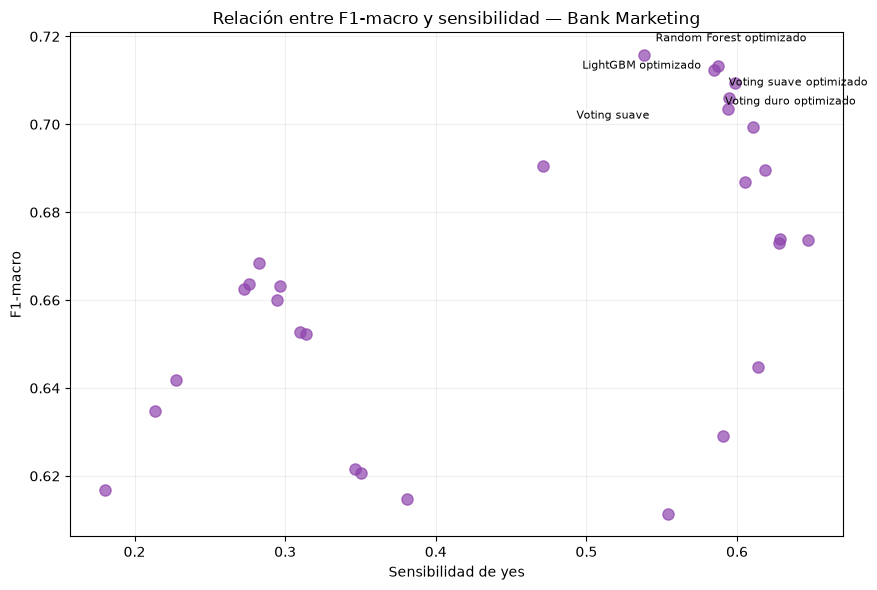

In [94]:
plt.figure(figsize=(9, 6))

plt.scatter(
    tabla_general_bank["Sensibilidad yes"],
    tabla_general_bank["F1-macro"],
    color="#8E44AD",
    alpha=0.7,
    s=65
)

desplazamientos = [
    (8, 10),
    (8, -14),
    (8, -25),
    (-110, 10),
    (-110, -15)
]

for (_, fila), desplazamiento in zip(
    tabla_general_bank.head(5).iterrows(),
    desplazamientos
):
    plt.annotate(
        fila["Modelo"],
        (
            fila["Sensibilidad yes"],
            fila["F1-macro"]
        ),
        xytext=desplazamiento,
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Sensibilidad de yes")
plt.ylabel("F1-macro")
plt.title("Relación entre F1-macro y sensibilidad — Bank Marketing")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

La gráfica muestra que **los modelos con mayor F1-macro no necesariamente presentan la mayor sensibilidad para la clase `yes`**. Por ejemplo, Random Forest optimizado obtuvo el mejor F1-macro (0.7157), pero su sensibilidad fue de 0.5386, mientras que XGBoost optimizado alcanzó una sensibilidad superior (0.6106), aunque con un F1-macro menor (0.6994).

También se observa que varios modelos se concentran en la región superior derecha, lo que indica que consiguieron combinar un F1-macro relativamente elevado con una buena capacidad para identificar clientes positivos.

Por otro lado, algunos clasificadores alcanzaron sensibilidades altas, pero presentaron un F1-macro considerablemente menor. Esto muestra que identificar una mayor proporción de casos positivos no garantiza un mejor desempeño general, ya que también es importante considerar los errores cometidos en ambas clases.

En general, la gráfica muestra la importancia de evaluar varias métricas, especialmente cuando se trabaja con datasets desbalanceados. Aunque Random Forest optimizado continúa siendo el mejor según F1-macro, otros modelos podrían ser preferibles si el objetivo principal fuera identificar la mayor cantidad posible de clientes que contrataron el depósito.

In [95]:
mejor_f1_bank = tabla_general_bank.loc[
    tabla_general_bank["F1-macro"].idxmax()
]

mejor_sensibilidad_bank = tabla_general_bank.loc[
    tabla_general_bank["Sensibilidad yes"].idxmax()
]

mas_rapido_bank = tabla_general_bank.loc[
    tabla_general_bank["Tiempo (s)"].idxmin()
]

print("Mejor F1-macro:")
print(
    f"{mejor_f1_bank['Modelo']}: "
    f"{mejor_f1_bank['F1-macro']:.4f}"
)

print("\nMayor sensibilidad de yes:")
print(
    f"{mejor_sensibilidad_bank['Modelo']}: "
    f"{mejor_sensibilidad_bank['Sensibilidad yes']:.4f}"
)

print("\nMenor tiempo de entrenamiento:")
print(
    f"{mas_rapido_bank['Modelo']}: "
    f"{mas_rapido_bank['Tiempo (s)']:.4f} s"
)

Mejor F1-macro:
Random Forest optimizado: 0.7157

Mayor sensibilidad de yes:
Stacking (balanced): 0.6470

Menor tiempo de entrenamiento:
kNN: 0.1325 s


A partir de la comparación general, se identificaron tres modelos destacados según las métricas evaluadas.

**Random Forest optimizado obtuvo el mayor F1-macro (0.7157)**, por lo que se seleccionó como el mejor clasificador de acuerdo con la métrica principal de la práctica.

Por otro lado, Stacking con metaclasificador balanceado presentó la mayor sensibilidad para la clase `yes` (0.6470), aunque su F1-macro fue inferior (0.6737) Finalmente, kNN presentó el menor tiempo promedio de entrenamiento (0.0935 segundos), aunque esto no considera el tiempo necesario para realizar predicciones.

En general, los resultados muestran que no existe un único modelo que destaque en todas las métricas. Por esta razón, la selección del clasificador depende del objetivo del problema. En esta práctica se priorizó F1-macro, por lo que **Random Forest optimizado fue seleccionado para el análisis final mediante una matriz de confusión**.

In [96]:
# Predicciones fuera de muestra
y_pred_rf_bank = cross_val_predict(
    clone(modelo_rf_optimizado_bank),
    X_bank,
    y_bank,
    cv=cv_bank,
    method="predict",
    n_jobs=1
)

print("F1-macro global:",
      round(f1_score(y_bank, y_pred_rf_bank, average="macro"), 4))

print("Sensibilidad yes:",
      round(recall_score(y_bank, y_pred_rf_bank, pos_label=1), 4))

F1-macro global: 0.7157
Sensibilidad yes: 0.5386


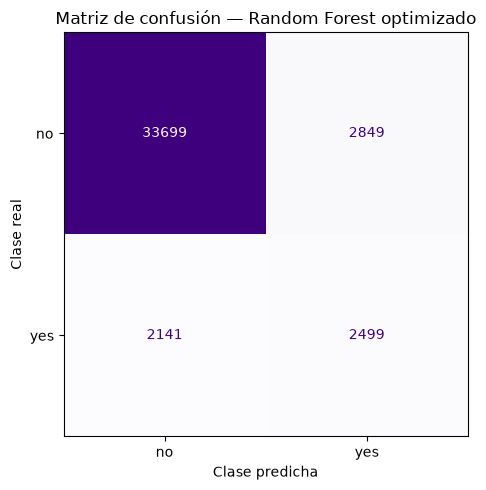

In [97]:
matriz_rf_bank = confusion_matrix(
    y_bank,
    y_pred_rf_bank,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf_bank,
    display_labels=["no", "yes"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Purples",
    values_format="d",
    colorbar=False
)

plt.title("Matriz de confusión — Random Forest optimizado")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

In [98]:
vn, fp, fn, vp = matriz_rf_bank.ravel()

print(f"Verdaderos negativos: {vn}")
print(f"Falsos positivos: {fp}")
print(f"Falsos negativos: {fn}")
print(f"Verdaderos positivos: {vp}")

print(f"\nClientes yes identificados: {vp / (vp + fn):.2%}")
print(f"Clientes yes no identificados: {fn / (vp + fn):.2%}")

Verdaderos negativos: 33699
Falsos positivos: 2849
Falsos negativos: 2141
Verdaderos positivos: 2499

Clientes yes identificados: 53.86%
Clientes yes no identificados: 46.14%


La matriz de confusión de Random Forest optimizado muestra que el modelo clasificó correctamente a 33,699 clientes de la clase `no` y a 2,499 de la clase `yes`. Sin embargo, también produjo 2,849 falsos positivos y 2,141 falsos negativos.

La sensibilidad de `yes` fue de **53.86%**, lo que significa que logró identificar poco más de la mitad de los clientes que realmente contrataron el depósito, mientras que el 46.14 % restante fue clasificado incorrectamente. Por otro lado, la especificidad fue de aproximadamente 92.20 %, indicando que el modelo identificó correctamente a la mayoría de los clientes que no contrataron el depósito.

Estos resultados muestran que, a pesar de utilizar ponderación de clases y optimización de hiperparámetros, **el desbalance continúa afectando la identificación de la clase minoritaria**.

In [102]:
# Recuperar el pipeline del Random Forest optimizado
modelo_final_bank = clone(modelo_rf_optimizado_bank)

# Entrenar con todos los datos disponibles
modelo_final_bank.fit(X_bank, y_bank)

# Guardar el modelo entrenado
joblib.dump(
    modelo_final_bank,
    "Adria-RandomForest-P2.joblib"
)

print("Modelo de Bank Marketing guardado correctamente.")

Modelo de Bank Marketing guardado correctamente.


## Comparación entre Parte 1 y Parte 2

En esta práctica se evaluaron diferentes familias de clasificadores y métodos de ensamble sobre dos datasets: uno relacionado con la deserción estudiantil y otro con la contratación de depósitos bancarios.

Aunque ambos problemas presentan desbalance de clases, tienen características muy diferentes. El conjunto de deserción estudiantil contiene tres categorías y 3,539 registros de entrenamiento, mientras que Bank Marketing es un problema de clasificación binaria con 41,188 registros.

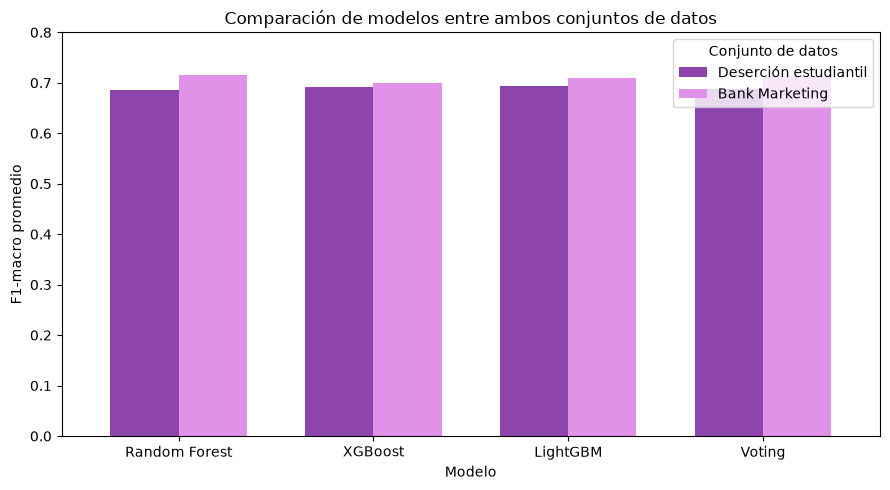

In [99]:
comparacion_partes = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "Voting"
    ],
    "Deserción estudiantil": [
        0.6865,
        0.6915,
        0.6945,
        0.6870
    ],
    "Bank Marketing": [
        0.7157,
        0.6994,
        0.7095,
        0.7132
    ]
})

ax = comparacion_partes.set_index("Modelo").plot(
    kind="bar",
    figsize=(9, 5),
    color=["#8E44AD", "#E091E8"],
    width=0.7
)

plt.title("Comparación de modelos entre ambos conjuntos de datos")
plt.ylabel("F1-macro promedio")
plt.xlabel("Modelo")
plt.ylim(0, 0.8)
plt.xticks(rotation=0)
plt.legend(title="Conjunto de datos")

plt.tight_layout()
plt.show()

Los resultados muestran que no existe un único algoritmo que sea el mejor para todos los conjuntos de datos.

En el problema de deserción estudiantil, LightGBM obtuvo el mayor F1-macro (0.6945), seguido de XGBoost (0.6915). En cambio, en Bank Marketing el mejor resultado correspondió a Random Forest optimizado (0.7157), seguido de Voting suave optimizado (0.7132).

Una posible explicación es que ambos problemas presentan estructuras diferentes. La deserción estudiantil requiere distinguir tres clases, mientras que Bank Marketing solamente tiene dos. Además, el conjunto bancario contiene una cantidad considerablemente mayor de registros, lo que puede influir en el aprendizaje de los clasificadores. Se puede inferir de esto que la utilidad de cada estrategia depende de las características del dataset. 

Una dificultad común en ambos conjuntos de datos fue la identificación de las clases menos representadas. En deserción estudiantil, LightGBM alcanzó una sensibilidad de 0.5811 para la clase Enrolled, mientras que en Bank Marketing Random Forest optimizado obtuvo una sensibilidad de 0.5386 para la clase yes.

Las matrices de confusión también evidenciaron estas dificultades. En el problema de deserción, LightGBM confundió parte de los estudiantes Enrolled con Dropout y Graduate. En Bank Marketing, Random Forest clasificó incorrectamente como no a 2,141 de los 4,640 clientes que realmente contrataron el depósito.

En ambos casos, los mejores modelos según F1-macro todavía presentaron dificultades para identificar la clase de interés, lo que demuestra que el desbalance sigue siendo un reto incluso después de aplicar estrategias de ensamble, ponderación y optimización. Esto confirma la importancia de analizar diferentes métricas 

## Conclusión

Con la realización de esta práctica se pudo observar que los métodos de ensamble pueden mejorar considerablemente el desempeño de los clasificadores, aunque sus beneficios dependen del conjunto de datos y de la estrategia utilizada. También se comprobó que aumentar la complejidad de un modelo no garantiza obtener mejores resultados, por lo que es importante comparar diferentes alternativas.

En el problema de deserción estudiantil, LightGBM obtuvo el mejor F1-macro (0.6945), seguido de XGBoost (0.6915). Por otro lado, en Bank Marketing, Random Forest optimizado alcanzó el mejor resultado (0.7157), mientras que Voting suave optimizado obtuvo un desempeño muy cercano (0.7132). Estas diferencias muestran que no existe una familia de algoritmos que sea superior en todos los problemas.

La optimización de hiperparámetros también resultó útil, especialmente en Bank Marketing, donde permitió mejorar los resultados de Random Forest, XGBoost y LightGBM. 

Otro aspecto relevante fue el manejo del desbalance de clases. Aunque las estrategias de ponderación mejoraron la sensibilidad en varios modelos, esto no siempre se tradujo en un mayor F1-macro. Las matrices de confusión mostraron que incluso los mejores clasificadores continuaron presentando dificultades para identificar correctamente las clases minoritarias. Esto demuestra la importancia de utilizar diferentes métricas y considerar el tipo de errores que se busca reducir.

Finalmente, la práctica permitió comprender mejor las diferencias entre Bagging, Boosting, Voting y Stacking, así como la importancia de la validación cruzada y la optimización de hiperparámetros. En general, la selección de un modelo no debe basarse únicamente en su complejidad o en una sola métrica, sino en un análisis de su desempeño, estabilidad, costo computacional y capacidad para resolver las necesidades específicas del problema

## Bibliografía

Ligdieli, & Ligdieli. (2019, 29 marzo). Métodos de ensamble de modelos. AprendeIA. https://aprendeia.com/2019/03/29/metodos-de-ensamble-de-modelos-machine-learning-ensemble-methods-en-espanol/

Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict Students' Dropout and Academic Success [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

¿Qué es el bagging? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/bagging

¿Qué es Boosting? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/boosting

Team, M. A. (2025, 27 diciembre). Soft Voting vs Hard Voting Ensembles: Which to Use. https://mcpanalytics.ai/articles/voting-ensemble-practical-guide-for-data-driven-decisions 

Ia, E. o.-. C., & Ia, E. o.-. C. (2025, 23 julio). ¿Qué es el Stacking en Inteligencia Artificial? Guía Completa sobre Stacked Generalization. Consultores IA. https://consultoresia.com/stacking-inteligencia-artificial-guia-completa-stacked-generalization/

Aznar, P. (2020, 17 junio). What is the difference between Extra Trees and Random Forest? | Quantdare. https://quantdare.com/what-is-the-difference-between-extra-trees-and-random-forest/

Arce, J. I. B. (2022, 14 junio). Light GBM vs XGBoost . ¿Cuál es mejor el algoritmo ? Juan Barrios. https://www.juanbarrios.com/light-gbm-vs-xgboost-cual-es-mejor-algoritmo/

MetricGate. (2026, 4 junio). SMOTE frente a ponderación de clases para datos desbalanceados. MetricGate. https://metricgate.com/blogs/es/smote-vs-class-weights/

### Declaración de uso de IA

Para el desarrollo de esta práctica se utilizó ChatGPT (OpenAI) como herramienta de apoyo. Los resultados, el código y las interpretaciones obtenidas fueron revisados y ajustados antes de su incorporación a la práctica. 